# La transformada de Fourier como enrollamiento y centro de masa

Una forma geométrica de entender la transformada de Fourier: **enrollamos** la señal $g(t)$ alrededor del origen del plano complejo y miramos dónde queda su **centro de masa**.

$$\underbrace{g(t)}_{\text{distancia al origen}}\;\cdot\;\underbrace{e^{-2\pi i f t}}_{\text{giro a } f \text{ vueltas/s}}$$

- $e^{-2\pi i f t}$ es un punto que gira por la circunferencia unidad, $f$ vueltas por segundo, en sentido **horario** por el signo menos.
- Al multiplicarlo por $g(t)$, la distancia al origen en cada instante es el valor de la señal. Se dibuja una curva enrollada.
- El **centro de masa** de esa curva es el promedio de todos sus puntos:

$$c(f) = \frac{1}{T}\int_0^T g(t)\,e^{-2\pi i f t}\,dt \qquad\Longrightarrow\qquad \boxed{G(f) = \int_0^T g(t)\,e^{-2\pi i f t}\,dt = T\cdot c(f)}$$

La transformada de Fourier **es** el centro de masa, escalado por la duración $T$.

**¿Por qué detecta frecuencias?** Si la velocidad de enrollamiento $f$ coincide con una frecuencia de la señal, los "picos" de $g(t)$ caen siempre en el mismo lado del círculo. La curva queda descompensada y el centro de masa se aleja del origen. Si no coincide, los picos se reparten por todo el círculo y el centro de masa queda cerca de 0.

Partes:
0. Ideas clave de los vídeos de 3Blue1Brown
1. La señal
2. Enrollarla a distintas frecuencias
3. El centro de masa en función de $f$ es la transformada
4. Animación: barrido de $f$
5. Módulo y fase: qué dice el centro de masa
6. Versión discreta: la DFT es $N$ veces el centro de masa de $N$ puntos

## 0. Ideas clave de los vídeos de 3Blue1Brown

Este notebook se apoya en dos vídeos. Las figuras de esta sección **recrean** sus imágenes clave con matplotlib, para tenerlas a mano junto al código. Para la explicación completa, mira los vídeos.

| [![Fourier](https://img.youtube.com/vi/h4PTucW3Rm0/hqdefault.jpg)](https://www.youtube.com/watch?v=h4PTucW3Rm0) | [![Euler](https://img.youtube.com/vi/-j8PzkZ70Lg/hqdefault.jpg)](https://www.youtube.com/watch?v=-j8PzkZ70Lg) |
|:---:|:---:|
| **¿Qué es la Transformada de Fourier? Una introducción visual** (3Blue1Brown Español) | **The Physics of Euler's Formula — Laplace Transform Prelude** (3Blue1Brown) |
| La máquina de enrollar y el centro de masa | Por qué aparecen las exponenciales complejas en física |

**Orden recomendado:** primero el de Euler (0.A–0.C), que explica *por qué* las ondas son exponenciales complejas, y después el de Fourier (0.D–0.E), que explica *cómo* detectarlas.

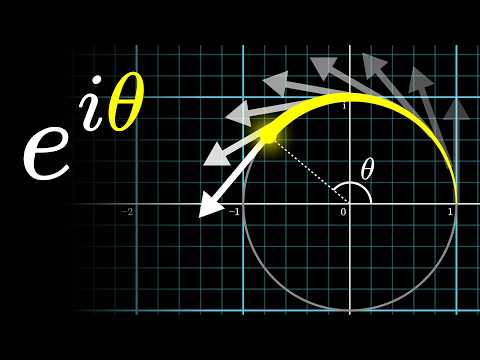

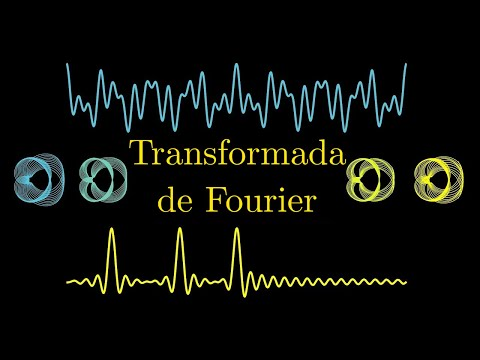

In [1]:
from IPython.display import YouTubeVideo, display
display(YouTubeVideo('-j8PzkZ70Lg', width=640, height=360))
display(YouTubeVideo('h4PTucW3Rm0', width=640, height=360))

### 0.A La exponencial es la función que es su propia derivada

$$\frac{d}{dt}e^{st} = s\,e^{st}$$

**La velocidad es proporcional a la posición.** Si $s$ es real, la exponencial crece o decae. Si $s = i\omega$, multiplicar por $i$ **gira 90°**, así que la velocidad $i\omega z$ es siempre **perpendicular** a la posición $z$. Un movimiento con la velocidad siempre perpendicular al radio es un **movimiento circular**:

$$z(t) = e^{i\omega t} = \cos\omega t + i\sin\omega t \qquad\text{(fórmula de Euler)}$$

Esto conecta con la ecuación de 1er orden $z' = i\omega z$ de la pregunta anterior.

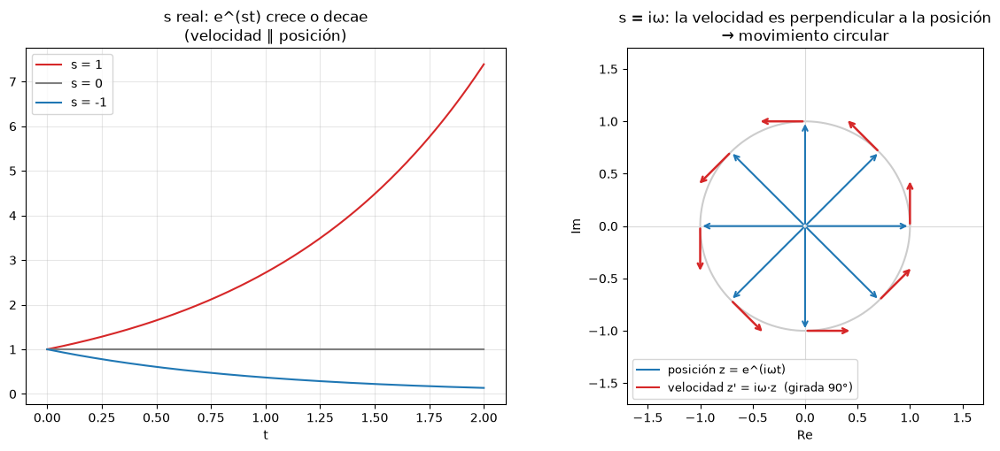

In [2]:
import numpy as np
import matplotlib.pyplot as plt

theta = np.linspace(0, 2 * np.pi, 400)
fig, axs = plt.subplots(1, 2, figsize=(12, 5.2))

# izquierda: e^{st} con s real -> la velocidad es paralela a la posición
ax = axs[0]
tt = np.linspace(0, 2, 200)
for s, col in [(1, 'tab:red'), (0, 'tab:gray'), (-1, 'tab:blue')]:
    ax.plot(tt, np.exp(s * tt), color=col, label=f's = {s}')
ax.set_title('s real: e^(st) crece o decae\n(velocidad ∥ posición)')
ax.set_xlabel('t'); ax.legend(); ax.grid(alpha=0.3)

# derecha: e^{iωt} -> la velocidad i·z es perpendicular a la posición
ax = axs[1]
ax.plot(np.cos(theta), np.sin(theta), color='0.8')
for a in np.linspace(0, 2 * np.pi, 8, endpoint=False):
    z = np.exp(1j * a)
    v = 1j * z * 0.45
    ax.annotate('', xy=(z.real, z.imag), xytext=(0, 0), arrowprops=dict(arrowstyle='->', color='tab:blue', lw=1.5))
    ax.annotate('', xy=(z.real + v.real, z.imag + v.imag), xytext=(z.real, z.imag),
                arrowprops=dict(arrowstyle='->', color='tab:red', lw=1.8))
ax.plot([], [], color='tab:blue', label='posición z = e^(iωt)')
ax.plot([], [], color='tab:red', label='velocidad z\' = iω·z  (girada 90°)')
ax.legend(loc='lower left', fontsize=9)
ax.set_title('s = iω: la velocidad es perpendicular a la posición\n→ movimiento circular')
ax.set_aspect('equal'); ax.set_xlim(-1.7, 1.7); ax.set_ylim(-1.7, 1.7)
ax.axhline(0, color='0.85', lw=0.8); ax.axvline(0, color='0.85', lw=0.8)
ax.set_xlabel('Re'); ax.set_ylabel('Im')
plt.tight_layout(); plt.show()

### 0.B El muelle: una oscilación real = dos fasores que giran en sentidos opuestos

La masa con muelle cumple $m\,x'' = -k\,x$. Probamos $x = e^{st}$, y la ecuación diferencial se convierte en **álgebra**:

$$m s^2 = -k \;\Rightarrow\; s = \pm i\omega,\quad \omega = \sqrt{k/m}$$

Las dos soluciones $e^{+i\omega t}$ y $e^{-i\omega t}$ giran en sentidos opuestos. Al sumarlas, las partes imaginarias se cancelan y queda una oscilación **real** sobre el eje horizontal:

$$\cos\omega t = \tfrac12 e^{i\omega t} + \tfrac12 e^{-i\omega t}$$

Por eso la DFT de un coseno tiene **dos** picos, en $+f$ y en $-f$ (ver el notebook de frecuencias negativas).

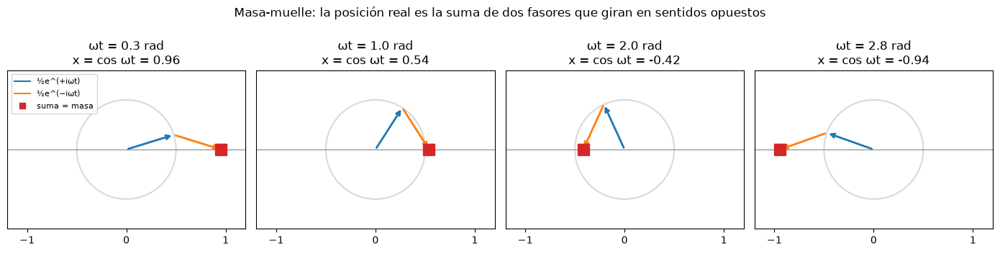

In [3]:
fig, axs = plt.subplots(1, 4, figsize=(14, 3.8))
for ax, wt in zip(axs, [0.3, 1.0, 2.0, 2.8]):
    zp, zm = 0.5 * np.exp(1j * wt), 0.5 * np.exp(-1j * wt)
    ax.plot(np.cos(theta) * 0.5, np.sin(theta) * 0.5, color='0.85')
    ax.annotate('', xy=(zp.real, zp.imag), xytext=(0, 0), arrowprops=dict(arrowstyle='->', color='tab:blue', lw=2))
    ax.annotate('', xy=(zp.real + zm.real, zp.imag + zm.imag), xytext=(zp.real, zp.imag),
                arrowprops=dict(arrowstyle='->', color='tab:orange', lw=2))
    ax.plot(np.cos(wt), 0, 's', color='tab:red', ms=12, zorder=3)
    ax.axhline(0, color='0.6', lw=1)
    ax.set_aspect('equal'); ax.set_xlim(-1.2, 1.2); ax.set_ylim(-0.8, 0.8)
    ax.set_title(f'ωt = {wt:.1f} rad\nx = cos ωt = {np.cos(wt):.2f}')
    ax.set_xticks([-1, 0, 1]); ax.set_yticks([])
axs[0].plot([], [], color='tab:blue', label='½e^(+iωt)')
axs[0].plot([], [], color='tab:orange', label='½e^(−iωt)')
axs[0].plot([], [], 's', color='tab:red', label='suma = masa')
axs[0].legend(fontsize=8, loc='upper left')
fig.suptitle('Masa-muelle: la posición real es la suma de dos fasores que giran en sentidos opuestos')
plt.tight_layout(); plt.show()

### 0.C Con rozamiento: $s$ complejo es una espiral

Con amortiguamiento, $m x'' + \mu x' + k x = 0$, las raíces son $s = -a \pm i\omega$:

$$e^{st} = \underbrace{e^{-at}}_{\text{decae}}\;\underbrace{e^{i\omega t}}_{\text{gira}}$$

- la **parte real** de $s$ da el crecimiento o decaimiento;
- la **parte imaginaria** de $s$ da la frecuencia de oscilación.

Un sonido real (una cuerda pulsada, una campana) es una suma de estas espirales. La transformada de Fourier mira solo el eje imaginario $s = i\omega$; la de Laplace, el plano $s$ entero (tema del siguiente vídeo de la serie).

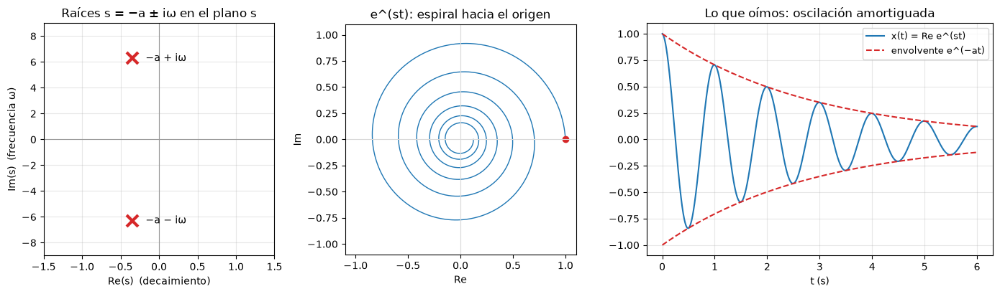

In [4]:
a, w = 0.35, 2 * np.pi
tt = np.linspace(0, 6, 2000)
z = np.exp((-a + 1j * w) * tt)

fig, axs = plt.subplots(1, 3, figsize=(14, 4.2), gridspec_kw={'width_ratios': [1, 1, 1.5]})
ax = axs[0]
ax.plot([-a, -a], [w, -w], 'x', color='tab:red', ms=12, mew=3)
ax.axhline(0, color='0.6', lw=0.8); ax.axvline(0, color='0.6', lw=0.8)
ax.set_xlim(-1.5, 1.5); ax.set_ylim(-9, 9)
ax.set_xlabel('Re(s)  (decaimiento)'); ax.set_ylabel('Im(s)  (frecuencia ω)')
ax.set_title('Raíces s = −a ± iω en el plano s')
ax.text(-a + 0.1, w, '  −a + iω', va='center'); ax.text(-a + 0.1, -w, '  −a − iω', va='center')
ax.grid(alpha=0.3)

ax = axs[1]
ax.plot(z.real, z.imag, color='tab:blue', lw=1)
ax.plot(1, 0, 'o', color='tab:red')
ax.set_aspect('equal'); ax.set_xlim(-1.1, 1.1); ax.set_ylim(-1.1, 1.1)
ax.axhline(0, color='0.85', lw=0.8); ax.axvline(0, color='0.85', lw=0.8)
ax.set_xlabel('Re'); ax.set_ylabel('Im'); ax.set_title('e^(st): espiral hacia el origen')

ax = axs[2]
ax.plot(tt, z.real, color='tab:blue', label='x(t) = Re e^(st)')
ax.plot(tt, np.exp(-a * tt), '--', color='tab:red', label='envolvente e^(−at)')
ax.plot(tt, -np.exp(-a * tt), '--', color='tab:red')
ax.set_xlabel('t (s)'); ax.legend(fontsize=9); ax.grid(alpha=0.3)
ax.set_title('Lo que oímos: oscilación amortiguada')
plt.tight_layout(); plt.show()

### 0.D La suma de tonos puros es una señal "desordenada"

El vídeo de Fourier empieza aquí: dos notas puras sumadas dan una onda cuyo patrón ya no se reconoce a simple vista. La pregunta es **cómo deshacer la suma**: recuperar 2 Hz y 3 Hz partiendo solo de la onda resultante.

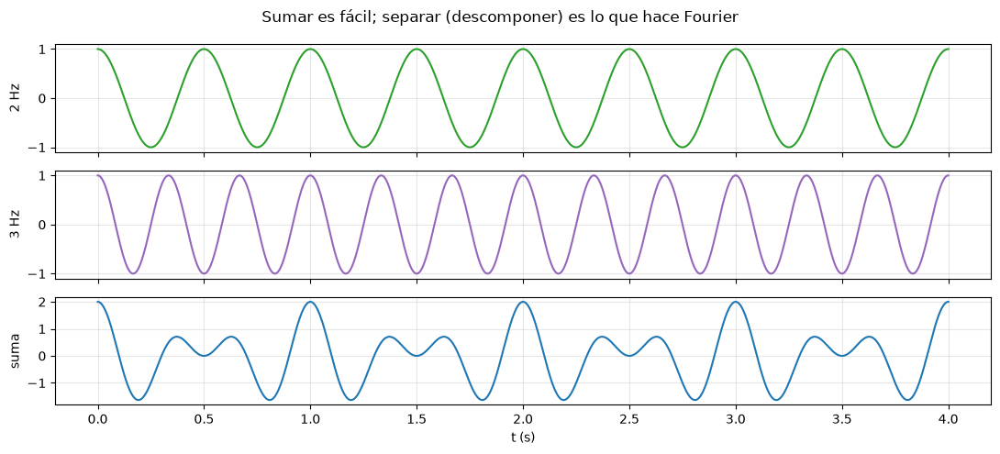

In [5]:
tt = np.linspace(0, 4, 4000)
a1 = np.cos(2 * np.pi * 2 * tt)
a2 = np.cos(2 * np.pi * 3 * tt)
fig, axs = plt.subplots(3, 1, figsize=(11, 5), sharex=True)
axs[0].plot(tt, a1, color='tab:green'); axs[0].set_ylabel('2 Hz')
axs[1].plot(tt, a2, color='tab:purple'); axs[1].set_ylabel('3 Hz')
axs[2].plot(tt, a1 + a2, color='tab:blue'); axs[2].set_ylabel('suma')
axs[2].set_xlabel('t (s)')
for ax in axs: ax.grid(alpha=0.3)
fig.suptitle('Sumar es fácil; separar (descomponer) es lo que hace Fourier')
plt.tight_layout(); plt.show()

### 0.E La máquina de enrollar: la coordenada x del centro de masa

La imagen central del vídeo: enrollamos la señal alrededor del origen a $f$ vueltas/s y dibujamos la **coordenada x del centro de masa** en función de $f$. Para la suma de 2 y 3 Hz aparecen **dos picos**, uno por tono. Como la transformada es lineal, el resultado es la suma de las transformadas de cada tono.

El resto del notebook desarrolla esta idea paso a paso.

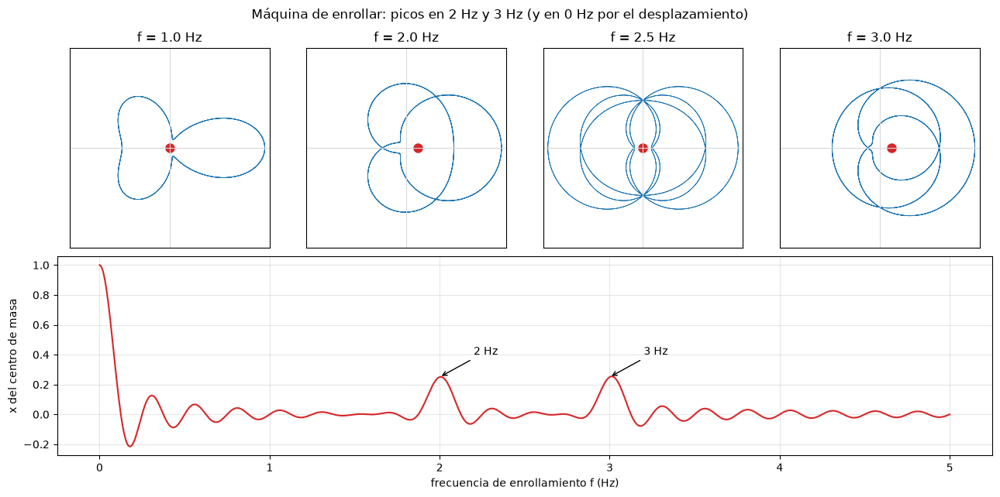

In [6]:
fs_ = 1000
tt = np.arange(0, 4.0, 1 / fs_)
gs = 1 + 0.5 * (np.cos(2 * np.pi * 2 * tt) + np.cos(2 * np.pi * 3 * tt))   # desplazada para que sea ≥ 0, como en el vídeo
ff = np.linspace(0, 5, 801)
com = np.array([(gs * np.exp(-2j * np.pi * f * tt)).mean() for f in ff])

fig = plt.figure(figsize=(13, 6.5))
for i, f in enumerate([1.0, 2.0, 2.5, 3.0]):
    ax = fig.add_subplot(2, 4, i + 1)
    zz = gs * np.exp(-2j * np.pi * f * tt); c = zz.mean()
    ax.plot(zz.real, zz.imag, lw=0.6, color='tab:blue')
    ax.plot(c.real, c.imag, 'o', color='tab:red', ms=8)
    ax.set_aspect('equal'); ax.set_xlim(-2.1, 2.1); ax.set_ylim(-2.1, 2.1)
    ax.axhline(0, color='0.85', lw=0.8); ax.axvline(0, color='0.85', lw=0.8)
    ax.set_title(f'f = {f} Hz'); ax.set_xticks([]); ax.set_yticks([])
ax = fig.add_subplot(2, 1, 2)
ax.plot(ff, com.real, color='tab:red')
ax.set_xlabel('frecuencia de enrollamiento f (Hz)'); ax.set_ylabel('x del centro de masa')
ax.grid(alpha=0.3)
for f in [2, 3]: ax.annotate(f'{f} Hz', xy=(f, 0.25), xytext=(f + 0.2, 0.4), arrowprops=dict(arrowstyle='->'))
fig.suptitle('Máquina de enrollar: picos en 2 Hz y 3 Hz (y en 0 Hz por el desplazamiento)')
plt.tight_layout(); plt.show()

In [7]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import animation
from IPython.display import HTML

fs = 1000                       # resolución del "tiempo continuo" (puntos/s)
T = 4.0                         # duración (s)
t = np.arange(0, T, 1 / fs)

def winding(g, f):
    """Curva enrollada g(t)·e^{-2πift} y su centro de masa."""
    z = g * np.exp(-2j * np.pi * f * t)
    return z, z.mean()

## 1. La señal

Usamos $g(t) = 1 + \cos(2\pi\cdot 3\,t)$, un tono de **3 Hz** con un desplazamiento constante (componente de 0 Hz). Así la señal es siempre positiva y la distancia al origen es fácil de leer. Más adelante usaremos una señal sin desplazamiento.

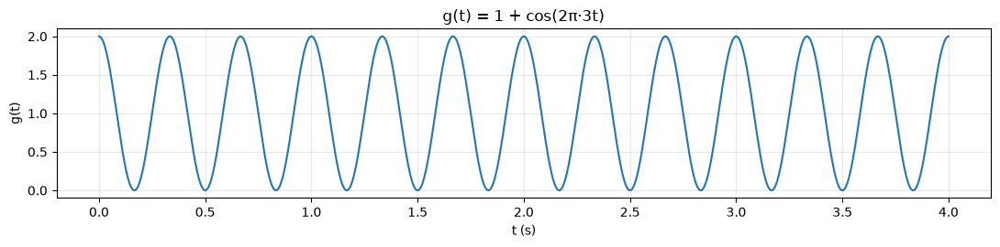

In [8]:
f0 = 3
g = 1 + np.cos(2 * np.pi * f0 * t)

plt.figure(figsize=(11, 2.8))
plt.plot(t, g, color='tab:blue')
plt.xlabel('t (s)'); plt.ylabel('g(t)')
plt.title('g(t) = 1 + cos(2π·3t)')
plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

## 2. Enrollarla a distintas frecuencias

Cada panel es la curva $g(t)\,e^{-2\pi i f t}$ en el plano complejo (eje horizontal: parte real, eje vertical: parte imaginaria) para una velocidad de enrollamiento $f$ distinta. El punto rojo es el **centro de masa**.

- $f = 0$: no hay giro, todo cae sobre el eje real positivo y el centro de masa es la media de $g$, que vale 1.
- $f \ne 3$: la curva forma una "flor" simétrica y el centro de masa queda en el origen.
- $f = 3$: cada máximo de $g$ cae en el mismo sitio (a la derecha). La curva se descompensa y el centro de masa se desplaza a 0.5.

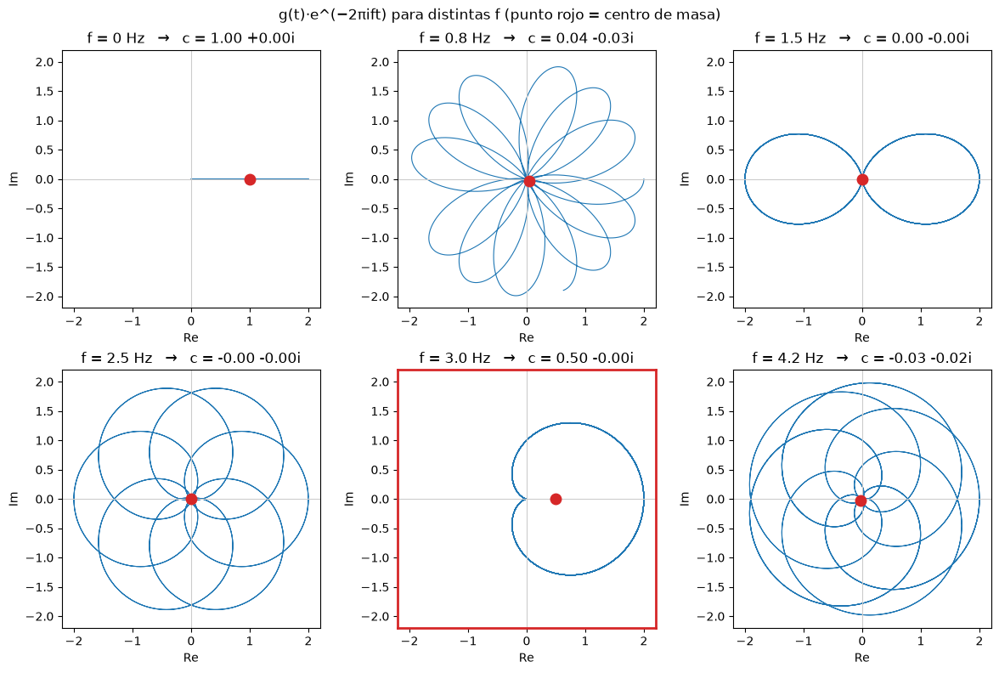

In [9]:
fs_test = [0, 0.8, 1.5, 2.5, 3.0, 4.2]

fig, axs = plt.subplots(2, 3, figsize=(12, 8))
for ax, f in zip(axs.ravel(), fs_test):
    z, c = winding(g, f)
    ax.plot(z.real, z.imag, color='tab:blue', lw=0.8)
    ax.plot(c.real, c.imag, 'o', color='tab:red', ms=9, zorder=3)
    ax.axhline(0, color='0.8', lw=0.8); ax.axvline(0, color='0.8', lw=0.8)
    ax.set_title(f'f = {f} Hz   →   c = {c.real:.2f} {c.imag:+.2f}i')
    ax.set_aspect('equal'); ax.set_xlim(-2.2, 2.2); ax.set_ylim(-2.2, 2.2)
    ax.set_xlabel('Re'); ax.set_ylabel('Im')
    if f == f0:
        for s in ax.spines.values(): s.set_color('tab:red'); s.set_linewidth(2)
fig.suptitle('g(t)·e^(−2πift) para distintas f (punto rojo = centro de masa)')
plt.tight_layout(); plt.show()

### 2b. ¿Qué trozo de la señal cae en cada vuelta?

En el instante $t$, el punto está en el ángulo $\theta = -2\pi f t$. Por eso:

- **Una vuelta completa dura $1/f$ segundos.** La vuelta $m$ enrolla el trozo $t \in [\,m/f,\;(m+1)/f\,)$.
- **Los instantes $t,\ t+\tfrac1f,\ t+\tfrac2f,\dots$ caen en la misma dirección**, uno encima de otro.
- **Cada vuelta contiene $f_0/f$ periodos de la señal**, es decir $f_0/f$ pétalos.

| $f$ | Duración de una vuelta | Periodos de $g$ por vuelta ($f_0/f$) | Qué pasa |
|---|---|---|---|
| 1 Hz | 1 s | 3 | 3 pétalos por vuelta; las 4 vueltas caen encima: **3 pétalos** |
| 1.5 Hz | 0.67 s | 2 | 2 pétalos por vuelta, siempre en el mismo sitio: **2 lóbulos** |
| 2.5 Hz | 0.4 s | 1.2 | cada vuelta se adelanta 0.2 periodos: los pétalos **se reparten** |
| **3 Hz** | **0.33 s = 1 periodo** | **1** | **cada vuelta es un periodo entero**: las 12 vueltas caen **exactamente encima** |

En la figura, cada vuelta tiene un color distinto, el mismo en la señal (izquierda) y en el enrollamiento (derecha). El punto negro es $t=0$, en el ángulo 0. Solo se muestran las 3 primeras vueltas, para que se vea qué trozo va a cada sitio.

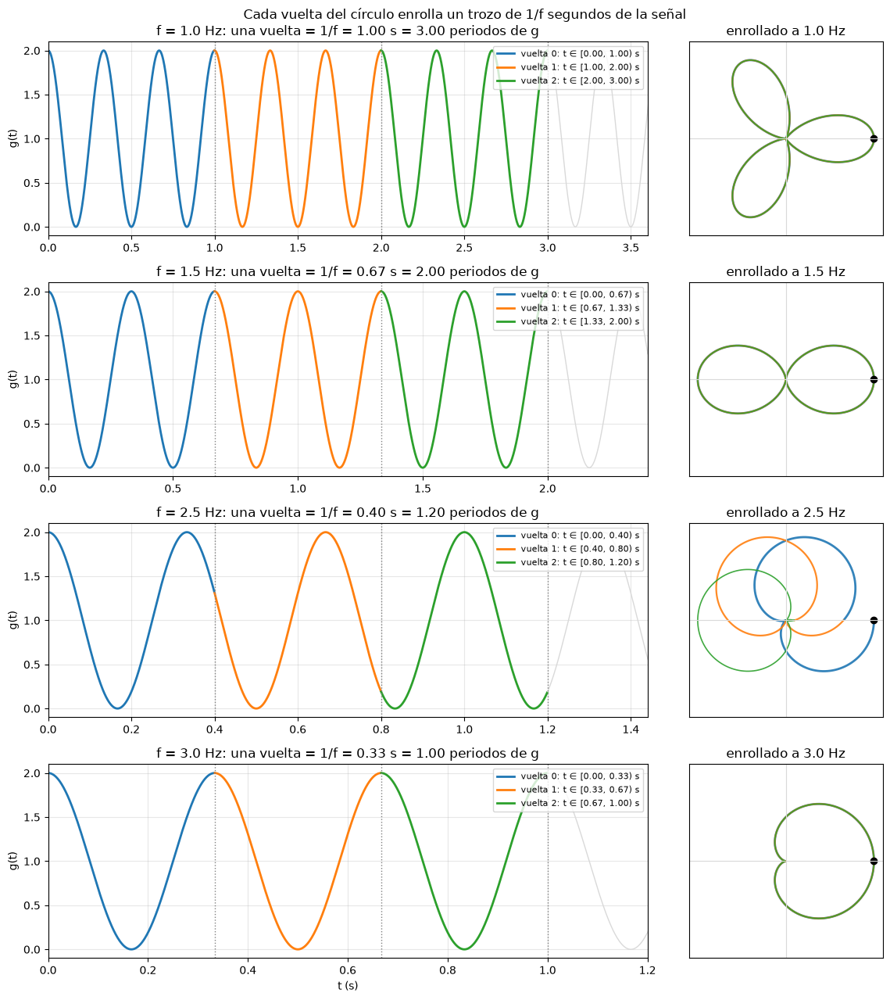

In [10]:
from matplotlib import colormaps

fig, axs = plt.subplots(4, 2, figsize=(12, 13), gridspec_kw={'width_ratios': [2.2, 1]})
cmap = colormaps['tab10']
for row, f in enumerate([1.0, 1.5, 2.5, 3.0]):
    vuelta = np.floor(t * f).astype(int)                # número de vuelta de cada instante
    z = g * np.exp(-2j * np.pi * f * t)
    ax_t, ax_z = axs[row]
    for m in range(3):                                  # primeras 3 vueltas
        sel = vuelta == m
        ax_t.plot(t[sel], g[sel], color=cmap(m), lw=2, label=f'vuelta {m}: t ∈ [{m/f:.2f}, {(m+1)/f:.2f}) s')
        ax_z.plot(z[sel].real, z[sel].imag, color=cmap(m), lw=2 - 0.4 * m, alpha=0.9)
    ax_t.plot(t[vuelta >= 3], g[vuelta >= 3], color='0.85', lw=1)
    for m in range(1, 4):
        ax_t.axvline(m / f, color='0.5', ls=':', lw=1)
    ax_t.set_xlim(0, min(T, 3.6 / f)); ax_t.set_ylabel('g(t)')
    ax_t.set_title(f'f = {f} Hz: una vuelta = 1/f = {1/f:.2f} s = {f0/f:.2f} periodos de g')
    ax_t.legend(fontsize=8, loc='upper right'); ax_t.grid(alpha=0.3)
    ax_z.plot(z[0].real, z[0].imag, 'ko', ms=6)
    ax_z.axhline(0, color='0.85', lw=0.8); ax_z.axvline(0, color='0.85', lw=0.8)
    ax_z.set_aspect('equal'); ax_z.set_xlim(-2.2, 2.2); ax_z.set_ylim(-2.2, 2.2)
    ax_z.set_xticks([]); ax_z.set_yticks([])
    ax_z.set_title(f'enrollado a {f} Hz')
axs[-1, 0].set_xlabel('t (s)')
fig.suptitle('Cada vuelta del círculo enrolla un trozo de 1/f segundos de la señal')
plt.tight_layout(); plt.show()

### 2c. ¿Por qué a $f = 3$ Hz sale una cardioide desplazada a la derecha?

**Cuando $f = f_0$, el ángulo del enrollamiento y la fase de la señal avanzan a la vez.** Llamemos $\varphi = 2\pi\cdot 3\,t$ a la fase de la señal. Al enrollar a 3 Hz, el ángulo es $\theta = -2\pi\cdot 3\,t = -\varphi$. Entonces el radio, **visto como función del ángulo**, es

$$r(\theta) = g = 1 + \cos\varphi = 1 + \cos\theta$$

y esa es la ecuación polar de una **cardioide**. Lo importante es que el radio depende **solo del ángulo**, no de en qué vuelta estés:

- **ángulo 0** (derecha): siempre cae un **máximo** de $g$, con $r = 2$;
- **ángulo 180°** (izquierda): siempre cae un **mínimo**, con $r = 0$;
- cada vuelta repite exactamente la misma curva, y las 12 vueltas se apilan encima.

**Toda la "masa" grande está a la derecha y a la izquierda no hay casi nada.** El centro de masa se desplaza a la derecha:

$$c = \big\langle (1+\cos\varphi)\,e^{-i\varphi}\big\rangle = \underbrace{\langle e^{-i\varphi}\rangle}_{0} + \underbrace{\langle\cos^2\varphi\rangle}_{1/2} - i\underbrace{\langle\cos\varphi\sin\varphi\rangle}_{0} = \tfrac12$$

**Si $f \ne f_0$, la sincronización se pierde.** Cada vuelta empieza en otra fase de la señal, así que los máximos caen unas veces a la derecha, otras arriba, otras a la izquierda… y se compensan.

En la figura, los **máximos** de $g$ están en rojo y los **mínimos** en azul, en la señal y en el enrollamiento. A 3 Hz todos los rojos caen en el mismo punto (derecha) y todos los azules en el origen. A 2.5 Hz se reparten por todo el círculo.

La fila de abajo muestra la **coordenada x** de la curva, $g(t)\cos(2\pi f t)$, que es lo que se promedia para obtener $\mathrm{Re}\,c$. A 3 Hz es casi siempre positiva y su media vale 0.5. A 2.5 Hz es igual de positiva que de negativa y su media vale 0.

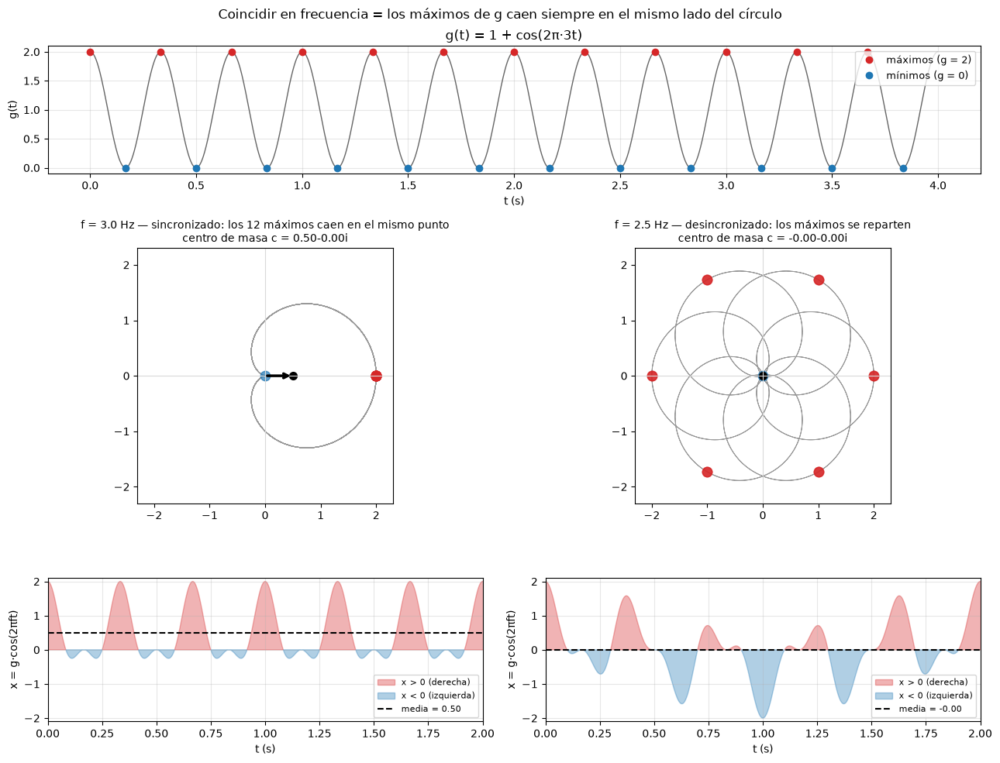

In [11]:
t_max = np.arange(0, T, 1 / f0)             # máximos de g: g = 2
t_min = t_max + 0.5 / f0                     # mínimos de g: g = 0

fig = plt.figure(figsize=(13, 10))
gsp = fig.add_gridspec(3, 2, height_ratios=[0.8, 1.6, 0.9])
ax_sig = fig.add_subplot(gsp[0, :])
ax_sig.plot(t, g, color='0.4', lw=1)
ax_sig.plot(t_max, 1 + np.cos(2 * np.pi * f0 * t_max), 'o', color='tab:red', label='máximos (g = 2)')
ax_sig.plot(t_min, 1 + np.cos(2 * np.pi * f0 * t_min), 'o', color='tab:blue', label='mínimos (g = 0)')
ax_sig.set_xlabel('t (s)'); ax_sig.set_ylabel('g(t)'); ax_sig.grid(alpha=0.3)
ax_sig.legend(fontsize=9, loc='upper right'); ax_sig.set_title('g(t) = 1 + cos(2π·3t)')

for col, f in enumerate([3.0, 2.5]):
    ax = fig.add_subplot(gsp[1, col])
    z, c = winding(g, f)
    ax.plot(z.real, z.imag, color='0.6', lw=0.7)
    zmax = 2 * np.exp(-2j * np.pi * f * t_max)
    ax.plot(zmax.real, zmax.imag, 'o', color='tab:red', ms=9, alpha=0.7)
    ax.plot(0, 0, 'o', color='tab:blue', ms=9, alpha=0.7)      # g = 0 cae siempre en el origen
    ax.annotate('', xy=(c.real, c.imag), xytext=(0, 0),
                arrowprops=dict(arrowstyle='->', color='k', lw=2.5))
    ax.plot(c.real, c.imag, 'ko', ms=7)
    ax.axhline(0, color='0.85', lw=0.8); ax.axvline(0, color='0.85', lw=0.8)
    ax.set_aspect('equal'); ax.set_xlim(-2.3, 2.3); ax.set_ylim(-2.3, 2.3)
    estado = 'sincronizado: los 12 máximos caen en el mismo punto' if f == f0 else 'desincronizado: los máximos se reparten'
    ax.set_title(f'f = {f} Hz — {estado}\ncentro de masa c = {c.real:.2f}{c.imag:+.2f}i', fontsize=10)

    ax2 = fig.add_subplot(gsp[2, col])
    xcoord = g * np.cos(2 * np.pi * f * t)
    ax2.fill_between(t, xcoord, 0, where=xcoord >= 0, color='tab:red', alpha=0.35, label='x > 0 (derecha)')
    ax2.fill_between(t, xcoord, 0, where=xcoord < 0, color='tab:blue', alpha=0.35, label='x < 0 (izquierda)')
    ax2.axhline(xcoord.mean(), color='k', ls='--', lw=1.5, label=f'media = {xcoord.mean():.2f}')
    ax2.set_xlim(0, 2); ax2.set_ylim(-2.1, 2.1)
    ax2.set_xlabel('t (s)'); ax2.set_ylabel('x = g·cos(2πft)'); ax2.grid(alpha=0.3)
    ax2.legend(fontsize=8, loc='lower right')
fig.suptitle('Coincidir en frecuencia = los máximos de g caen siempre en el mismo lado del círculo')
plt.tight_layout(); plt.show()

### 2d. En continuo: ¿qué son las "vueltas que sobran"?

(Anticipa la sección 6b. La idea se entiende igual aquí, en continuo.)

En la 2b, el color marcaba las vueltas **del enrollamiento**, cada una de $1/f$ segundos. Ahora miramos otra cosa: **cuánto gira el producto respecto al enrollamiento**.

La señal $g(t) = 1 + \cos(2\pi\cdot 3t)$ son **tres fasores**: uno de 0 Hz (amplitud 1) y dos de $\pm 3$ Hz (amplitud ½). Al enrollar a $f$, el de $+3$ Hz se convierte en

$$\tfrac12 e^{i2\pi\cdot 3t}\,e^{-i2\pi f t} = \tfrac12 e^{i2\pi (3 - f)\,t}$$

y **sigue girando**, despacio, a $(3-f)$ vueltas por segundo. Durante los $T$ segundos que observamos, da

$$\boxed{d = (f_0 - f)\,T \ \text{ vueltas sobrantes}}$$

Es el equivalente continuo de $k_0 - k$ en la DFT. De hecho, en la DFT el bin $k$ es la frecuencia $k/T$, así que $k_0 - k = (f_0 - f)\,T$.

**Qué significan físicamente:**
- **$1/|f_0 - f|$ es el periodo de batido.** Es el tiempo que tarda la flor en dar una vuelta completa, como la rueda del estroboscopio que parece girar despacio. Cada **pasada** de la figura dura un periodo de batido.
- **$d = 0$** ($f = 3$): no hay batido. Los pétalos se quedan quietos en el mismo sitio y $|c| = ½$.
- **$d$ entero** ($f = 2.5$ → $d = 2$): en los 4 s, los pétalos dan **dos vueltas completas** alrededor del círculo y se reparten por igual: $c = 0$ **exactamente**. Por eso en la 2b el centro de masa a 2.5 Hz era 0. En la figura, los pétalos azules quedan **tapados** por los naranjas: las dos pasadas son completas y caen en las mismas posiciones.
- **$d = 0.5$** ($f = 2.875$ Hz, solo 0.125 Hz de diferencia): en los 4 s, los pétalos solo **rotan media vuelta**. Se reparten en medio círculo y el centro de masa se encoge a $\approx 2/\pi$ de ½.
- **$d = 1.5$** ($f = 2.625$): una vuelta completa, que se compensa, más media vuelta suelta: un centro de masa pequeño.

**La curva resultante** es la sinc continua (el núcleo de Dirichlet de la DFT cuando $N\to\infty$):

$$|c(f)| \approx \tfrac12\left|\frac{\sin(\pi d)}{\pi d}\right|,\qquad d = (f_0-f)\,T$$

Tiene ceros en $f = f_0 \pm m/T$, es decir cada $1/T = 0.25$ Hz. Son los ceros que se ven alrededor del pico en la gráfica de la sección 3. **Observar más tiempo ($T$ mayor) estrecha el pico**: la resolución en frecuencia es $\Delta f \approx 1/T$.

En la figura, cada **pasada** (cada periodo de batido) tiene un color, el mismo en la señal y en el enrollamiento. Los puntos grandes son los **máximos de $g$**, las puntas de los pétalos, que llevan casi toda la "masa". Hay que fijarse en cómo se desplazan alrededor del círculo de una pasada a la siguiente.

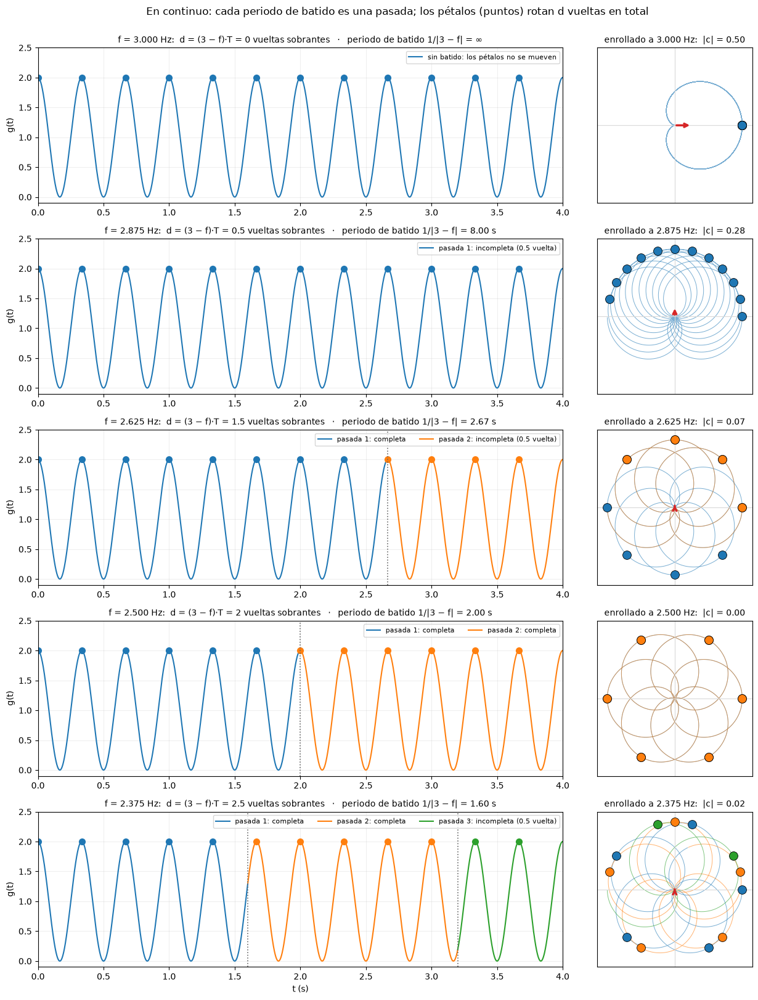

In [12]:
from matplotlib import colormaps
cmap_c = colormaps['tab10']
ds = [0, 0.5, 1.5, 2.0, 2.5]
t_tips = np.arange(0, T, 1 / f0)            # máximos de g (puntas de los pétalos)

fig, axs = plt.subplots(len(ds), 2, figsize=(13, 3.3 * len(ds)), gridspec_kw={'width_ratios': [2.3, 1]})
for row, dd in enumerate(ds):
    f = f0 - dd / T
    z, c = winding(g, f)
    pas = np.floor(np.abs(dd) * t / T + 1e-9).astype(int)          # pasada (periodo de batido) de cada instante
    pas_tip = np.floor(np.abs(dd) * t_tips / T + 1e-9).astype(int)
    z_tip = 2 * np.exp(-2j * np.pi * f * t_tips)
    ax_t, ax_z = axs[row]
    for m in range(pas.max() + 1):
        sel = pas == m
        frac = min(1.0, abs(dd) - m) if dd != 0 else 1.0
        lab = ('sin batido: los pétalos no se mueven' if dd == 0 else
               f'pasada {m + 1}: ' + ('completa' if frac >= 1 - 1e-9 else f'incompleta ({frac:.1f} vuelta)'))
        ax_t.plot(t[sel], g[sel], color=cmap_c(m), lw=1.5, label=lab)
        ax_z.plot(z[sel].real, z[sel].imag, color=cmap_c(m), lw=0.7, alpha=0.6)
        st = pas_tip == m
        ax_t.plot(t_tips[st], np.full(st.sum(), 2.0), 'o', color=cmap_c(m), ms=7)
        ax_z.plot(z_tip[st].real, z_tip[st].imag, 'o', color=cmap_c(m), ms=10, mec='k', mew=0.6, zorder=3)
    if dd != 0:
        for m in range(1, int(np.ceil(abs(dd)))):
            ax_t.axvline(m * T / abs(dd), color='0.4', ls=':', lw=1.2)
    batido = '∞' if dd == 0 else f'{T / abs(dd):.2f} s'
    ax_t.set_title(f'f = {f:.3f} Hz:  d = (3 − f)·T = {dd:g} vueltas sobrantes   ·   periodo de batido 1/|3 − f| = {batido}', fontsize=10)
    ax_t.set_xlim(0, T); ax_t.set_ylim(-0.1, 2.5); ax_t.set_ylabel('g(t)')
    ax_t.legend(fontsize=8, loc='upper right', ncol=3); ax_t.grid(alpha=0.2)

    ax_z.annotate('', xy=(c.real, c.imag), xytext=(0, 0), arrowprops=dict(arrowstyle='->', color='tab:red', lw=2.5))
    ax_z.axhline(0, color='0.85', lw=0.8); ax_z.axvline(0, color='0.85', lw=0.8)
    ax_z.set_xlim(-2.3, 2.3); ax_z.set_ylim(-2.3, 2.3); ax_z.set_box_aspect(1)
    ax_z.set_xticks([]); ax_z.set_yticks([])
    ax_z.set_title(f'enrollado a {f:.3f} Hz:  |c| = {abs(c):.2f}', fontsize=10)
axs[-1, 0].set_xlabel('t (s)')
fig.suptitle('En continuo: cada periodo de batido es una pasada; los pétalos (puntos) rotan d vueltas en total')
plt.tight_layout(rect=(0, 0, 1, 0.98)); plt.show()

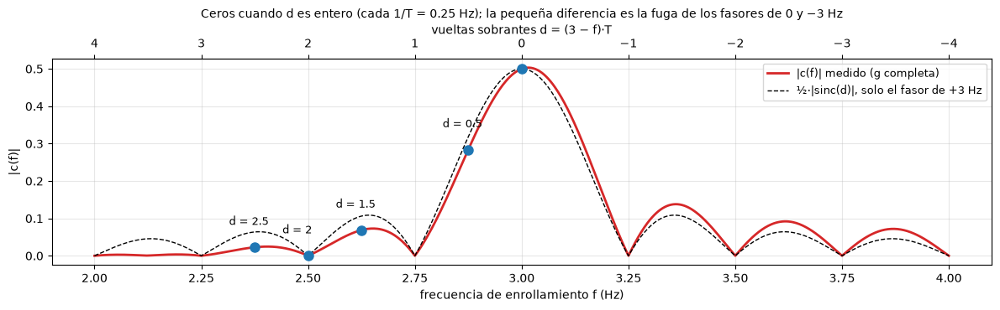

In [13]:
ff = np.linspace(2, 4, 801)
Cc = np.array([abs(winding(g, f)[1]) for f in ff])
dd_axis = (f0 - ff) * T

fig, ax = plt.subplots(figsize=(12, 3.8))
ax.plot(ff, Cc, color='tab:red', lw=2, label='|c(f)| medido (g completa)')
ax.plot(ff, 0.5 * np.abs(np.sinc(dd_axis)), 'k--', lw=1, label='½·|sinc(d)|, solo el fasor de +3 Hz')
for dd in ds:
    f = f0 - dd / T
    ax.plot(f, abs(winding(g, f)[1]), 'o', color='tab:blue', ms=8)
    if dd != 0: ax.annotate(f'd = {dd:g}', xy=(f, abs(winding(g, f)[1])), xytext=(f - 0.06, abs(winding(g, f)[1]) + 0.06), fontsize=9)
ax.set_xlabel('frecuencia de enrollamiento f (Hz)'); ax.set_ylabel('|c(f)|'); ax.grid(alpha=0.3)
sec = ax.secondary_xaxis('top', functions=(lambda f: (f0 - f) * T, lambda d: f0 - d / T))
sec.set_xlabel('vueltas sobrantes d = (3 − f)·T')
ax.set_title('Ceros cuando d es entero (cada 1/T = 0.25 Hz); la pequeña diferencia es la fuga de los fasores de 0 y −3 Hz', fontsize=10)
ax.legend(fontsize=9)
plt.tight_layout(); plt.show()

#### Los dos corredores: "cuánto gira el producto respecto al enrollamiento"

En el enrollamiento hay **dos cosas girando a la vez**:

1. **Corredor A (rojo) = una flecha de la señal.** Por Euler, $\cos(2\pi\cdot 3t)$ está hecho de flechas que giran. Seguimos la que da **3 vueltas por segundo**.
2. **Corredor B (azul) = el papel que gira al enrollar**, a **$f$ vueltas por segundo**.

Lo que queda dibujado en el papel es **dónde ve B a A**: la **ventaja** de A sobre B. Las vueltas enteras no se notan, porque en un círculo una vuelta completa te deja en el mismo sitio. Solo cuenta la diferencia:

$$\text{ventaja}(t) = (3 - f)\,t \ \text{vueltas} \qquad\Rightarrow\qquad \text{al final } (t=T):\ d = (3-f)\,T$$

| t (s) | Vueltas de A | Vueltas de B (f = 2.875) | **Ventaja de A** |
|---|---|---|---|
| 0 | 0 | 0 | **0** |
| 1 | 3 | 2.875 | **0.125** |
| 2 | 6 | 5.75 | **0.25** |
| 3 | 9 | 8.625 | **0.375** |
| 4 | 12 | 11.5 | **0.5** |

Primero, la ventaja en función del tiempo para los tres casos. Después, la animación.

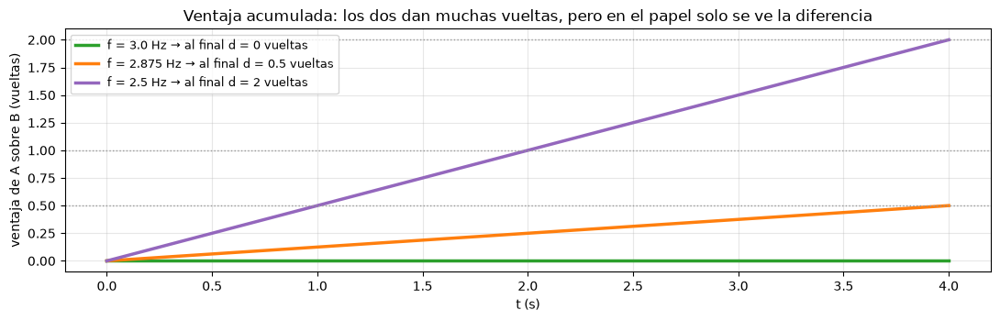

In [14]:
casos_r = [3.0, 2.875, 2.5]
col_r = ['tab:green', 'tab:orange', 'tab:purple']
tt_r = np.linspace(0, T, 400)

fig, ax = plt.subplots(figsize=(11, 3.6))
for f, col in zip(casos_r, col_r):
    ax.plot(tt_r, (f0 - f) * tt_r, color=col, lw=2.5, label=f'f = {f} Hz → al final d = {(f0 - f) * T:g} vueltas')
for v in [0.5, 1, 2]:
    ax.axhline(v, color='0.6', ls=':', lw=1)
ax.set_xlabel('t (s)'); ax.set_ylabel('ventaja de A sobre B (vueltas)')
ax.set_title('Ventaja acumulada: los dos dan muchas vueltas, pero en el papel solo se ve la diferencia')
ax.legend(fontsize=9); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

**Animación** (una columna por caso):

- **Arriba, la pista vista desde fuera.** A (rojo) da 3 vueltas/s y B (azul) da $f$ vueltas/s. Los dos giran rápido, y a simple vista es difícil ver quién gana.
- **Abajo, lo que ve B, que es lo que queda dibujado en el papel.** B está siempre en la posición de referencia (flecha azul, a la derecha), y A aparece donde le permite su ventaja. Cada fotograma deja una **marca** roja. La flecha negra es el **centro de masa de las marcas** hasta ese momento.

Lo que se observa:
- **f = 3:** A está siempre junto a B. Las marcas se apilan en un punto y el centro de masa no se mueve de ahí: **pico**.
- **f = 2.875:** A se adelanta despacio y en 4 s solo recorre **media vuelta**. Las marcas cubren medio círculo y el centro de masa queda a medio camino.
- **f = 2.5:** A da **dos vueltas completas** alrededor de B. Las marcas cubren todo el círculo por igual, y al final el centro de masa vuelve al centro: **0**.

Aquí la flecha de A tiene longitud 1, así que el centro de masa de las marcas vale 1, 0.64 y 0. En la señal real esa flecha mide ½ (la mitad de la amplitud del coseno), y por eso en la 2d salían 0.5, ≈0.3 y 0.

(Ejecuta la celda para generar la animación si no aparece.)

In [15]:
dt_r = 1 / 24
t_fr = np.arange(0, T + dt_r / 2, dt_r)            # fotogramas
fig, axs = plt.subplots(2, 3, figsize=(10, 6.8), dpi=48)
th_c = np.linspace(0, 2 * np.pi, 200)
art = []
for col, f in enumerate(casos_r):
    a_top, a_bot = axs[0, col], axs[1, col]
    for a in (a_top, a_bot):
        a.plot(np.cos(th_c), np.sin(th_c), color='0.85', lw=2)
        a.set_xlim(-1.35, 1.35); a.set_ylim(-1.35, 1.35); a.set_box_aspect(1)
        a.set_xticks([]); a.set_yticks([])
    a_top.set_title(f'pista: A = 3 vueltas/s, B = {f} vueltas/s', fontsize=10)
    a_bot.set_title(f'visto desde B (el papel)\nd final = (3 − {f})·4 = {(f0 - f) * T:g} vueltas', fontsize=10)
    a_bot.annotate('', xy=(1.0, 0), xytext=(0, 0), arrowprops=dict(arrowstyle='->', color='tab:blue', lw=1.5, alpha=0.6))
    dA, = a_top.plot([], [], 'o', color='tab:red', ms=14, label='A (señal)')
    dB, = a_top.plot([], [], 'o', color='tab:blue', ms=14, label='B (papel)')
    txt = a_top.text(0, 0, '', ha='center', va='center', fontsize=9)
    marks, = a_bot.plot([], [], 'o', color='tab:red', ms=4, alpha=0.35)
    dA_rel, = a_bot.plot([], [], 'o', color='tab:red', ms=14)
    com_line, = a_bot.plot([], [], color='k', lw=2.5)
    com_dot, = a_bot.plot([], [], 'ko', ms=7)
    txt_b = a_bot.text(0, -1.3, '', ha='center', va='bottom', fontsize=9)
    art.append((f, dA, dB, txt, marks, dA_rel, com_line, com_dot, txt_b))
axs[0, 0].legend(loc='upper left', fontsize=8, bbox_to_anchor=(-0.05, 1.02))
plt.tight_layout()

def upd_r(i):
    ti = t_fr[i]
    out = []
    for f, dA, dB, txt, marks, dA_rel, com_line, com_dot, txt_b in art:
        aA, aB = 2 * np.pi * f0 * ti, 2 * np.pi * f * ti
        dA.set_data([np.cos(aA)], [np.sin(aA)])
        dB.set_data([0.82 * np.cos(aB)], [0.82 * np.sin(aB)])
        txt.set_text(f't = {ti:.2f} s\nA: {f0 * ti:.2f} v\nB: {f * ti:.2f} v')
        rel = 2 * np.pi * (f0 - f) * t_fr[:i + 1]          # posición de A vista desde B
        zr = np.exp(1j * rel)
        marks.set_data(zr.real, zr.imag)
        dA_rel.set_data([zr[-1].real], [zr[-1].imag])
        c = zr.mean()
        com_line.set_data([0, c.real], [0, c.imag]); com_dot.set_data([c.real], [c.imag])
        txt_b.set_text(f'ventaja = {(f0 - f) * ti:.3f} vueltas\n|centro de masa| = {abs(c):.2f}')
        out += [dA, dB, txt, marks, dA_rel, com_line, com_dot, txt_b]
    return out

anim_r = animation.FuncAnimation(fig, upd_r, frames=len(t_fr), interval=80, blit=True)
plt.close(fig)
HTML(anim_r.to_jshtml())

## 3. El centro de masa en función de $f$ es la transformada

Calculamos $c(f)$ para muchas frecuencias y dibujamos su parte real, su parte imaginaria y su módulo. Hay dos picos:

- en **$f=0$**: el desplazamiento constante (la media de la señal),
- en **$f=3$**: el tono de 3 Hz.

Multiplicando por $T$ obtenemos (salvo error de discretización) $G(f) = \int_0^T g(t)e^{-2\pi i f t}dt$. Lo comprobamos con una integral numérica independiente (`np.trapezoid`).

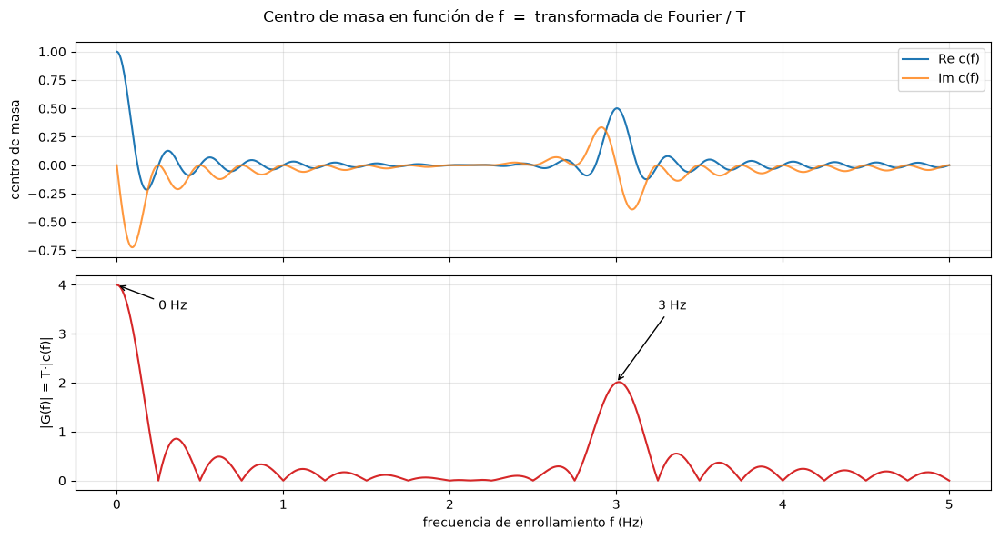

G(3.0) por integral : 1.9980-0.0000j
T · c(3.0)          : 2.0000-0.0000j


In [16]:
freqs = np.linspace(0, 5, 1001)
C = np.array([winding(g, f)[1] for f in freqs])

fig, axs = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
axs[0].plot(freqs, C.real, label='Re c(f)', color='tab:blue')
axs[0].plot(freqs, C.imag, label='Im c(f)', color='tab:orange', alpha=0.8)
axs[0].set_ylabel('centro de masa'); axs[0].legend(); axs[0].grid(alpha=0.3)
axs[1].plot(freqs, np.abs(C) * T, color='tab:red')
axs[1].set_ylabel('|G(f)| = T·|c(f)|'); axs[1].set_xlabel('frecuencia de enrollamiento f (Hz)')
axs[1].grid(alpha=0.3)
for f_mark in [0, f0]:
    axs[1].annotate(f'{f_mark} Hz', xy=(f_mark, abs(winding(g, f_mark)[1]) * T),
                    xytext=(f_mark + 0.25, 3.5), arrowprops=dict(arrowstyle='->'))
fig.suptitle('Centro de masa en función de f  =  transformada de Fourier / T')
plt.tight_layout(); plt.show()

f_check = 3.0
G_integral = np.trapezoid(g * np.exp(-2j * np.pi * f_check * t), t)
print(f'G({f_check}) por integral : {G_integral:.4f}')
print(f'T · c({f_check})          : {T * winding(g, f_check)[1]:.4f}')

## 4. Animación: barrido de $f$

A la izquierda, la curva enrollada y su centro de masa (rojo). A la derecha, el rastro que va dejando $|c(f)|$. Cuando $f$ pasa por 3 Hz, la "flor" se descompensa y el centro de masa salta hacia fuera.

(Ejecuta la celda para generarla; no se guarda en el notebook porque pesa varios MB. Usa los controles bajo la animación para reproducirla o moverla fotograma a fotograma.)

In [17]:
f_anim = np.linspace(0, 4.5, 91)
C_anim = np.array([winding(g, f)[1] for f in f_anim])

fig, (axl, axr) = plt.subplots(1, 2, figsize=(10, 4.4), dpi=70,
                               gridspec_kw={'width_ratios': [1, 1.4]})
line, = axl.plot([], [], color='tab:blue', lw=0.8)
dot, = axl.plot([], [], 'o', color='tab:red', ms=9)
axl.axhline(0, color='0.8', lw=0.8); axl.axvline(0, color='0.8', lw=0.8)
axl.set_aspect('equal'); axl.set_xlim(-2.2, 2.2); axl.set_ylim(-2.2, 2.2)
axl.set_xlabel('Re'); axl.set_ylabel('Im')
title = axl.set_title('')

axr.set_xlim(0, f_anim[-1]); axr.set_ylim(0, 1.1)
axr.set_xlabel('f (Hz)'); axr.set_ylabel('|c(f)|'); axr.grid(alpha=0.3)
trace, = axr.plot([], [], color='tab:red')
cursor = axr.axvline(0, color='0.5', ls='--')
plt.tight_layout()

def update(i):
    z, c = winding(g, f_anim[i])
    line.set_data(z.real, z.imag)
    dot.set_data([c.real], [c.imag])
    title.set_text(f'f = {f_anim[i]:.2f} Hz')
    trace.set_data(f_anim[:i + 1], np.abs(C_anim[:i + 1]))
    cursor.set_xdata([f_anim[i]])
    return line, dot, title, trace, cursor

anim = animation.FuncAnimation(fig, update, frames=len(f_anim), interval=120, blit=True)
plt.close(fig)
HTML(anim.to_jshtml())

## 5. Módulo y fase: qué dice el centro de masa

El centro de masa es un número complejo, así que tiene:

- **módulo** $|c(f)|$: cuánto contiene la señal de la frecuencia $f$, es decir lo descompensada que queda la curva;
- **ángulo** $\arg c(f)$: **hacia dónde** queda descompensada. Indica la **fase** de esa componente.

Ahora usamos una señal **sin desplazamiento** con dos tonos, $g_2(t) = \cos(2\pi\cdot 2t + \varphi) + 0.5\cos(2\pi\cdot 5t)$. Al enrollar a 2 Hz, el centro de masa queda a distancia 0.5 del origen (la mitad de la amplitud, porque $\cos = \tfrac12 e^{i\cdot} + \tfrac12 e^{-i\cdot}$). Su ángulo es exactamente $\varphi$: si desfasamos la señal, el centro de masa **gira** el mismo ángulo.

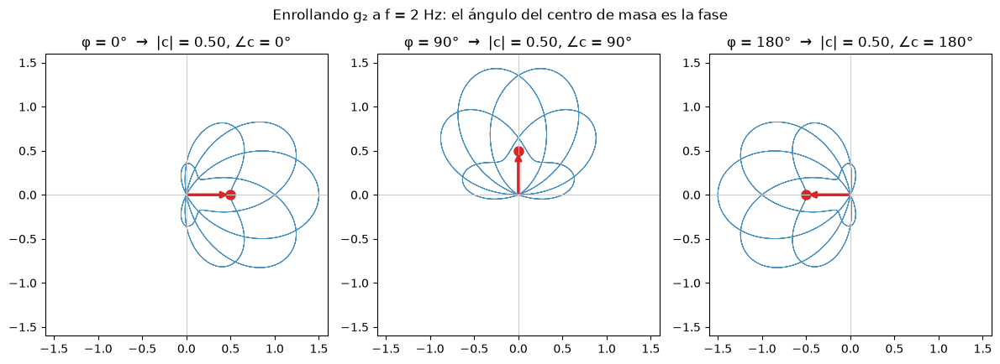

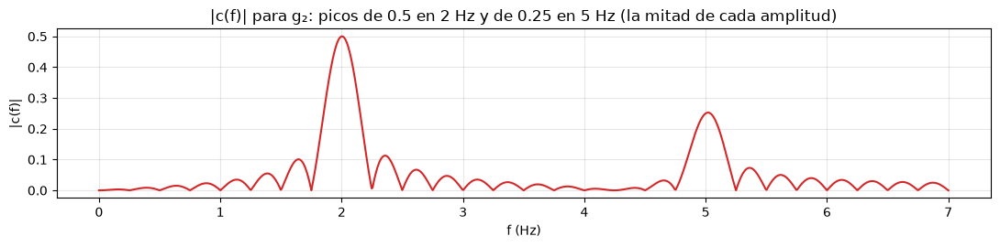

In [18]:
phis = [0, np.pi / 2, np.pi]
fig, axs = plt.subplots(1, 3, figsize=(12, 4.3))
for ax, phi in zip(axs, phis):
    g2 = np.cos(2 * np.pi * 2 * t + phi) + 0.5 * np.cos(2 * np.pi * 5 * t)
    z, c = winding(g2, 2)
    ax.plot(z.real, z.imag, color='tab:blue', lw=0.6, alpha=0.8)
    ax.annotate('', xy=(c.real, c.imag), xytext=(0, 0),
                arrowprops=dict(arrowstyle='->', color='tab:red', lw=2.5))
    ax.plot(c.real, c.imag, 'o', color='tab:red', ms=8)
    ax.axhline(0, color='0.8', lw=0.8); ax.axvline(0, color='0.8', lw=0.8)
    ax.set_aspect('equal'); ax.set_xlim(-1.6, 1.6); ax.set_ylim(-1.6, 1.6)
    ax.set_title(f'φ = {np.degrees(phi):.0f}°  →  |c| = {abs(c):.2f}, ∠c = {np.degrees(np.angle(c)):.0f}°')
fig.suptitle('Enrollando g₂ a f = 2 Hz: el ángulo del centro de masa es la fase')
plt.tight_layout(); plt.show()

g2 = np.cos(2 * np.pi * 2 * t) + 0.5 * np.cos(2 * np.pi * 5 * t)
C2 = np.array([winding(g2, f)[1] for f in freqs * 1.4])
plt.figure(figsize=(11, 2.8))
plt.plot(freqs * 1.4, np.abs(C2), color='tab:red')
plt.xlabel('f (Hz)'); plt.ylabel('|c(f)|')
plt.title('|c(f)| para g₂: picos de 0.5 en 2 Hz y de 0.25 en 5 Hz (la mitad de cada amplitud)')
plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

### 5b. La fase es el ángulo del centro de masa

El centro de masa es un número complejo $c = |c|\,e^{i\,\arg c}$. Ya hemos visto que su **distancia al origen** $|c|$ es la magnitud. Ahora vemos que su **ángulo** $\arg c$ es **la fase** de la componente.

**Por qué, según el vídeo de Euler.** Una componente con fase $\varphi$ se escribe con dos fasores:

$$\cos(2\pi f_0 t + \varphi) = \tfrac12\,\underbrace{e^{i\varphi}}_{\text{posición inicial}}\,e^{i2\pi f_0 t} \;+\; \tfrac12\,e^{-i\varphi}\,e^{-i2\pi f_0 t}$$

La fase $\varphi$ es **el ángulo desde el que arranca el fasor** en $t=0$. Multiplicar por $e^{i\varphi}$ es **girar** $\varphi$ radianes.

**Qué hace el enrollamiento, según el vídeo de Fourier.** Al enrollar a $f = f_0$, multiplicamos por $e^{-i2\pi f_0 t}$:
- el primer fasor **deja de girar** y se queda quieto en $\tfrac12 e^{i\varphi}$;
- el segundo gira al doble de velocidad y su media es 0.

$$c(f_0) = \tfrac12\,e^{i\varphi} \quad\Rightarrow\quad |c| = \tfrac{A}{2}, \qquad \arg c = \varphi$$

**Lectura geométrica:** desfasar la señal un ángulo $\varphi$ **gira toda la flor** ese mismo ángulo. El centro de masa gira con ella: no cambia su distancia al origen, solo su dirección.

**Retardo en el tiempo.** Retrasar la señal $\tau$ segundos es desfasarla $\varphi = -2\pi f_0 \tau$. Por eso la fase indica *cómo está alineada en el tiempo* cada componente (diapositiva 3).

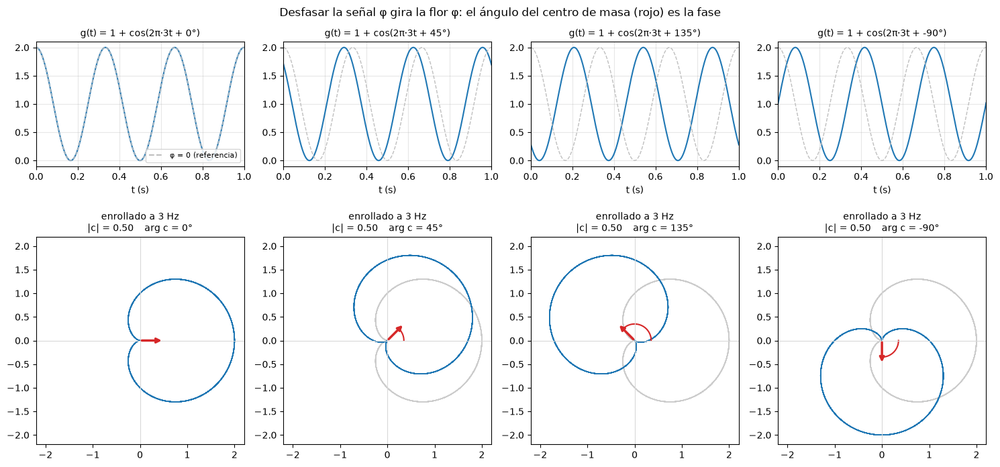

In [19]:
def arc(ax, ang, r=0.35, color='k'):
    """Dibuja el arco del ángulo `ang` (rad) desde el eje real positivo."""
    a = np.linspace(0, ang, 60)
    ax.plot(r * np.cos(a), r * np.sin(a), color=color, lw=1.5)

phis_deg = [0, 45, 135, -90]
fig, axs = plt.subplots(2, 4, figsize=(15, 7.5), gridspec_kw={'height_ratios': [1, 2.4]})
for col, ph_deg in enumerate(phis_deg):
    ph = np.radians(ph_deg)
    gp = 1 + np.cos(2 * np.pi * f0 * t + ph)

    ax = axs[0, col]
    ax.plot(t, gp, color='tab:blue')
    ax.plot(t, g, color='0.75', lw=1, ls='--')
    ax.set_xlim(0, 1); ax.set_title(f'g(t) = 1 + cos(2π·3t + {ph_deg}°)', fontsize=10)
    ax.set_xlabel('t (s)'); ax.grid(alpha=0.3)

    ax = axs[1, col]
    z, c = winding(gp, f0)
    z_ref, _ = winding(g, f0)
    ax.plot(z_ref.real, z_ref.imag, color='0.8', lw=1, ls='--')      # flor con φ = 0
    ax.plot(z.real, z.imag, color='tab:blue', lw=1)
    ax.annotate('', xy=(c.real, c.imag), xytext=(0, 0),
                arrowprops=dict(arrowstyle='->', color='tab:red', lw=2.5))
    arc(ax, np.angle(c), color='tab:red')
    ax.axhline(0, color='0.85', lw=0.8); ax.axvline(0, color='0.85', lw=0.8)
    ax.set_aspect('equal'); ax.set_xlim(-2.2, 2.2); ax.set_ylim(-2.2, 2.2)
    ax.set_title(f'enrollado a 3 Hz\n|c| = {abs(c):.2f}    arg c = {np.degrees(np.angle(c)) + 0.0:.0f}°'.replace('-0°', '0°'), fontsize=10)
axs[0, 0].plot([], [], color='0.75', ls='--', label='φ = 0 (referencia)'); axs[0, 0].legend(fontsize=8, loc='lower right')
fig.suptitle('Desfasar la señal φ gira la flor φ: el ángulo del centro de masa (rojo) es la fase')
plt.tight_layout(); plt.show()

#### Espectro de magnitud y de fase

Lo mismo para todas las frecuencias a la vez. Con una señal de dos tonos de fases distintas,

$$g_3(t) = \cos(2\pi\cdot 2t + 60°) + 0.6\cos(2\pi\cdot 5t - 120°)$$

dibujamos $|c(f)|$ y $\arg c(f)$. En cada pico, el **ángulo del centro de masa coincide con la fase** de ese tono.

Lejos de los picos, $|c| \approx 0$: el centro de masa está casi en el origen y su ángulo **no significa nada** (es ruido numérico). Por eso la fase solo se interpreta donde hay magnitud. Esa es la razón de que los espectros de fase como el de la diapositiva 3 parezcan tan "ruidosos".

Dentro de cada pico, la fase no es plana: baja en línea recta. Es el efecto de observar la señal solo durante $T$ segundos, una ventana centrada en $T/2$ que equivale a un retardo de $T/2$ (ver el apartado de retardo más abajo). La fase de la componente es el valor **exactamente en el pico**.

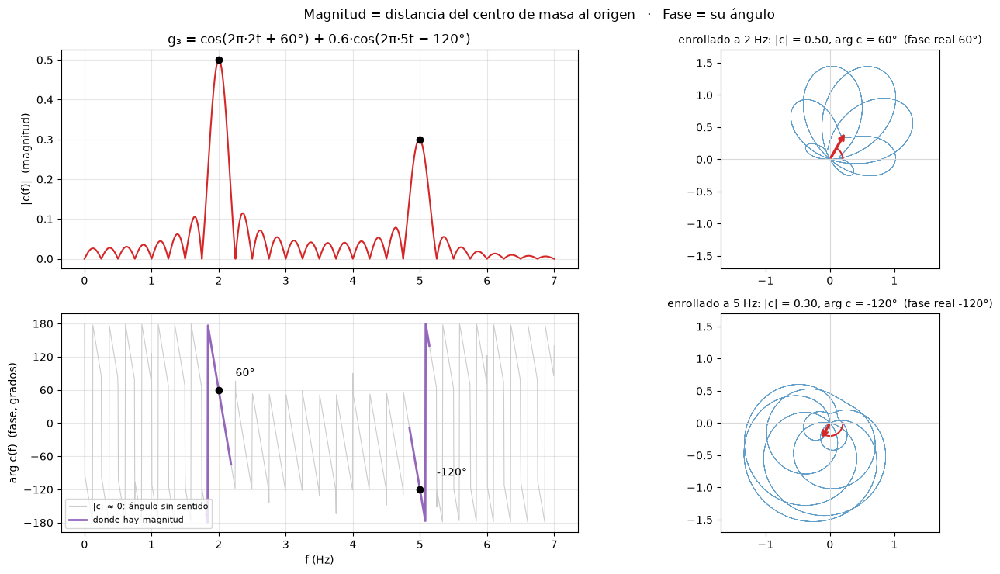

DFT bin 2: |X|/N = 0.50   angle(X) = 60.0°
DFT bin 5: |X|/N = 0.30   angle(X) = -120.0°


In [20]:
ph1, ph2 = np.radians(60), np.radians(-120)
g3 = np.cos(2 * np.pi * 2 * t + ph1) + 0.6 * np.cos(2 * np.pi * 5 * t + ph2)
ff = np.linspace(0, 7, 1401)
C3 = np.array([winding(g3, f)[1] for f in ff])
mag, ang = np.abs(C3), np.degrees(np.angle(C3))
valid = mag > 0.3 * mag.max()        # solo cerca de los picos

fig = plt.figure(figsize=(14, 7.5))
gsp = fig.add_gridspec(2, 3, width_ratios=[2.2, 1, 1])
ax_m = fig.add_subplot(gsp[0, 0]); ax_p = fig.add_subplot(gsp[1, 0], sharex=ax_m)
ax_m.plot(ff, mag, color='tab:red'); ax_m.set_ylabel('|c(f)|  (magnitud)'); ax_m.grid(alpha=0.3)
ax_m.set_title('g₃ = cos(2π·2t + 60°) + 0.6·cos(2π·5t − 120°)')
ax_p.plot(ff, ang, color='0.8', lw=0.8, label='|c| ≈ 0: ángulo sin sentido')
ax_p.plot(np.where(valid, ff, np.nan), np.where(valid, ang, np.nan), color='tab:purple', lw=2, label='donde hay magnitud')
ax_p.set_ylabel('arg c(f)  (fase, grados)'); ax_p.set_xlabel('f (Hz)')
ax_p.set_yticks([-180, -120, -60, 0, 60, 120, 180]); ax_p.grid(alpha=0.3); ax_p.legend(fontsize=8, loc='lower left')

for row, (fk, phk) in enumerate([(2, ph1), (5, ph2)]):
    c = winding(g3, fk)[1]
    ax_m.plot(fk, abs(c), 'ko'); ax_p.plot(fk, np.degrees(np.angle(c)), 'ko')
    ax_p.annotate(f'{np.degrees(np.angle(c)):.0f}°', xy=(fk, np.degrees(np.angle(c))),
                  xytext=(fk + 0.25, np.degrees(np.angle(c)) + 25))
    ax = fig.add_subplot(gsp[row, 1:])
    z = g3 * np.exp(-2j * np.pi * fk * t)
    ax.plot(z.real, z.imag, color='tab:blue', lw=0.5, alpha=0.7)
    ax.annotate('', xy=(c.real, c.imag), xytext=(0, 0), arrowprops=dict(arrowstyle='->', color='tab:red', lw=2.5))
    arc(ax, np.angle(c), r=0.2, color='tab:red')
    ax.axhline(0, color='0.85', lw=0.8); ax.axvline(0, color='0.85', lw=0.8)
    ax.set_aspect('equal'); ax.set_xlim(-1.7, 1.7); ax.set_ylim(-1.7, 1.7)
    ax.set_title(f'enrollado a {fk} Hz: |c| = {abs(c):.2f}, arg c = {np.degrees(np.angle(c)):.0f}°  (fase real {np.degrees(phk):.0f}°)', fontsize=10)
fig.suptitle('Magnitud = distancia del centro de masa al origen   ·   Fase = su ángulo')
plt.tight_layout(); plt.show()

# lo mismo con la DFT: N muestras, tonos en bins enteros
N3, fs3 = 64, 64
n3 = np.arange(N3)
x3 = np.cos(2 * np.pi * 2 * n3 / fs3 + ph1) + 0.6 * np.cos(2 * np.pi * 5 * n3 / fs3 + ph2)
X3 = np.fft.fft(x3)
for k in [2, 5]:
    print(f'DFT bin {k}: |X|/N = {abs(X3[k])/N3:.2f}   angle(X) = {np.degrees(np.angle(X3[k])):.1f}°')

#### Retardo en el tiempo: el centro de masa gira

Si retrasamos la señal $\tau$ segundos, $g(t-\tau)$, cada componente se desfasa $\varphi = -2\pi f_0\tau$. El centro de masa **gira en sentido horario** mientras su distancia al origen se mantiene constante. Al retrasar un periodo entero ($\tau = 1/f_0$), da una vuelta completa y vuelve al mismo sitio.

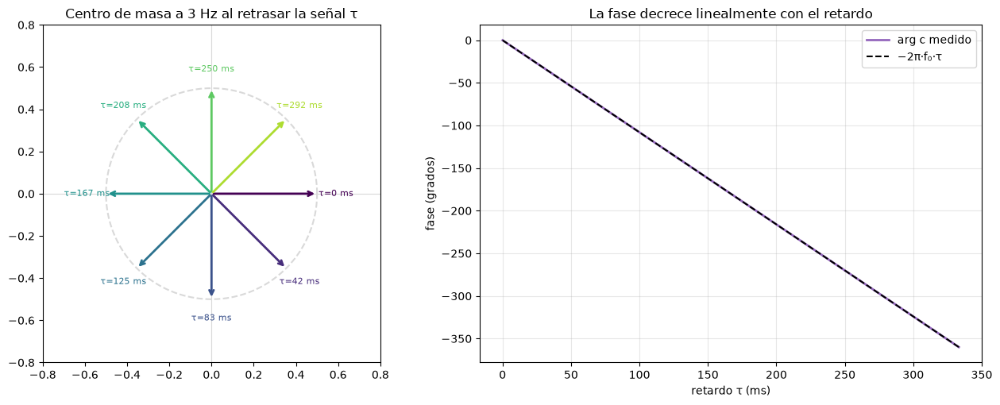

In [21]:
taus = np.linspace(0, 1 / f0, 9)
fig, axs = plt.subplots(1, 2, figsize=(13, 5.2), gridspec_kw={'width_ratios': [1, 1.3]})
ax = axs[0]
cmap = plt.get_cmap('viridis')
for i, tau in enumerate(taus[:-1]):
    gd = 1 + np.cos(2 * np.pi * f0 * (t - tau))
    c = winding(gd, f0)[1]
    col = cmap(i / (len(taus) - 1))
    ax.annotate('', xy=(c.real, c.imag), xytext=(0, 0), arrowprops=dict(arrowstyle='->', color=col, lw=2))
    ax.text(1.18 * c.real, 1.18 * c.imag, f'τ={tau*1000:.0f} ms', fontsize=8, ha='center', va='center', color=col)
th = np.linspace(0, 2 * np.pi, 200)
ax.plot(0.5 * np.cos(th), 0.5 * np.sin(th), color='0.85', ls='--')
ax.set_aspect('equal'); ax.set_xlim(-0.8, 0.8); ax.set_ylim(-0.8, 0.8)
ax.axhline(0, color='0.85', lw=0.8); ax.axvline(0, color='0.85', lw=0.8)
ax.set_title('Centro de masa a 3 Hz al retrasar la señal τ')

ax = axs[1]
tau_fine = np.linspace(0, 1 / f0, 200)
arg_meas = [np.angle(winding(1 + np.cos(2 * np.pi * f0 * (t - tau)), f0)[1]) for tau in tau_fine]
ax.plot(tau_fine * 1000, np.degrees(np.unwrap(arg_meas)), color='tab:purple', lw=2, label='arg c medido')
ax.plot(tau_fine * 1000, np.degrees(-2 * np.pi * f0 * tau_fine), 'k--', label='−2π·f₀·τ')
ax.set_xlabel('retardo τ (ms)'); ax.set_ylabel('fase (grados)'); ax.grid(alpha=0.3); ax.legend()
ax.set_title('La fase decrece linealmente con el retardo')
plt.tight_layout(); plt.show()

## 6. Versión discreta: la DFT es $N$ veces el centro de masa de $N$ puntos

En la DFT no hay una curva continua, sino **$N$ puntos** $x[n]$. Enrollar a la frecuencia del bin $k$ significa girar $2\pi k/N$ radianes por muestra:

$$X[k] = \sum_{n=0}^{N-1} x[n]\,e^{-j2\pi kn/N} = N\cdot\underbrace{\frac{1}{N}\sum_{n=0}^{N-1} x[n]\,e^{-j2\pi kn/N}}_{\text{centro de masa de los } N \text{ puntos}}$$

Es la misma imagen, pero en lugar de una curva tenemos $N$ "masas" puntuales en el plano. Abajo: $N=32$ muestras de un coseno en el bin 4 (más un desplazamiento), enrolladas a $k=3$, $k=4$ y $k=5$. Comprobamos que $N\cdot c$ coincide con `np.fft.fft`.

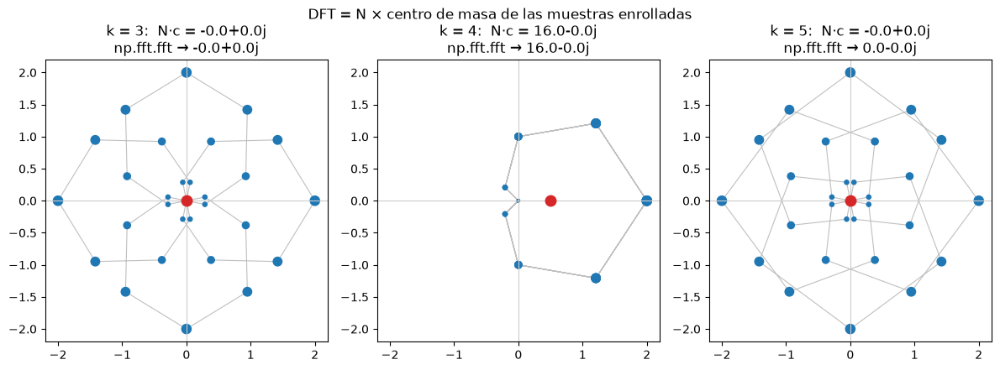

¿N·c[k] == fft(x)[k] para todo k? True


In [22]:
N = 32
n = np.arange(N)
x = 1 + np.cos(2 * np.pi * 4 * n / N)
X = np.fft.fft(x)

fig, axs = plt.subplots(1, 3, figsize=(12, 4.3))
for ax, k in zip(axs, [3, 4, 5]):
    z = x * np.exp(-2j * np.pi * k * n / N)
    c = z.mean()
    ax.plot(np.append(z.real, z.real[0]), np.append(z.imag, z.imag[0]), color='0.75', lw=0.8)
    ax.scatter(z.real, z.imag, s=30 * x + 5, color='tab:blue', zorder=2)
    ax.plot(c.real, c.imag, 'o', color='tab:red', ms=9, zorder=3)
    ax.axhline(0, color='0.8', lw=0.8); ax.axvline(0, color='0.8', lw=0.8)
    ax.set_aspect('equal'); ax.set_xlim(-2.2, 2.2); ax.set_ylim(-2.2, 2.2)
    ax.set_title(f'k = {k}:  N·c = {N*c.real:.1f}{N*c.imag:+.1f}j\nnp.fft.fft → {X[k].real:.1f}{X[k].imag:+.1f}j')
fig.suptitle('DFT = N × centro de masa de las muestras enrolladas')
plt.tight_layout(); plt.show()

centros = np.array([(x * np.exp(-2j * np.pi * k * n / N)).mean() for k in range(N)])
print('¿N·c[k] == fft(x)[k] para todo k?', np.allclose(N * centros, X))

### 6b. La velocidad de giro que sobra (leakage, diapositiva 11)

Ahora la señal es una **sinusoide compleja**, $x[n] = e^{j2\pi k_0 n/N}$, que **ya gira por sí sola**: $k_0$ vueltas por ventana, en sentido antihorario. El enrollamiento del bin $k$ gira $k$ vueltas por ventana en sentido horario. Al multiplicar, los ángulos se suman y **las velocidades se restan**:

$$x[n]\,e^{-j2\pi kn/N} = e^{j2\pi (k_0 - k)\,n/N}$$

El producto **sigue girando** a $k_0 - k$ vueltas por ventana. Eso es lo que *sobra*: el giro de la señal que el enrollamiento no ha cancelado.

| Giro sobrante $k_0-k$ | Las $N$ muestras quedan… | Centro de masa | $\lvert X[k]\rvert$ |
|---|---|---|---|
| 0 | todas en el mismo punto | distancia 1 | $N$ |
| entero (±1, ±2…) | repartidas en vueltas completas | 0 | 0 |
| ±0.5 | en media circunferencia | $2/\pi \approx 0.64$ | $\approx 0.64\,N$ |
| ±1.5, ±2.5… | vueltas completas + media vuelta suelta | pequeño, ≠ 0 | "colas" del leakage |

La figura está justo debajo, y a continuación hay una guía para leerla panel a panel.

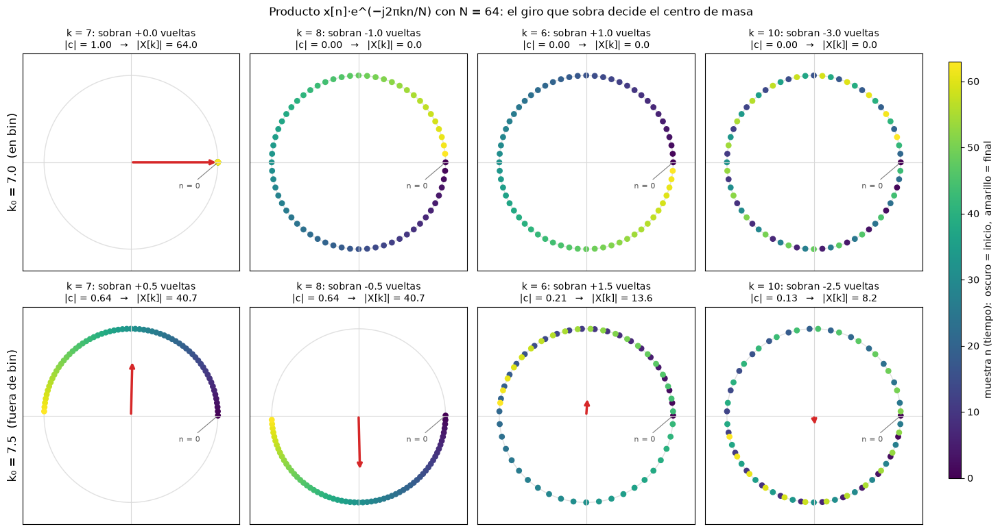

In [23]:
N = 64
n = np.arange(N)
k_bins = [7, 8, 6, 10]

fig, axs = plt.subplots(2, 4, figsize=(15, 8))
for row, k0 in enumerate([7.0, 7.5]):
    x = np.exp(2j * np.pi * k0 * n / N)
    for col, k in enumerate(k_bins):
        ax = axs[row, col]
        p = x * np.exp(-2j * np.pi * k * n / N)          # producto: gira a (k0 - k) vueltas/ventana
        c = p.mean()
        ax.plot(np.cos(theta), np.sin(theta), color='0.88', lw=1)
        sc = ax.scatter(p.real, p.imag, c=n, cmap='viridis', s=28, zorder=2, vmin=0, vmax=N - 1)
        ax.annotate('n = 0', xy=(1, 0), xytext=(0.55, -0.3), fontsize=8, color='0.3',
                    arrowprops=dict(arrowstyle='-', color='0.5', lw=0.8))
        ax.annotate('', xy=(c.real, c.imag), xytext=(0, 0),
                    arrowprops=dict(arrowstyle='->', color='tab:red', lw=2.5))
        ax.axhline(0, color='0.85', lw=0.8); ax.axvline(0, color='0.85', lw=0.8)
        ax.set_aspect('equal'); ax.set_xlim(-1.25, 1.25); ax.set_ylim(-1.25, 1.25)
        ax.set_xticks([]); ax.set_yticks([])
        ax.set_title(f'k = {k}: sobran {k0 - k:+.1f} vueltas\n|c| = {abs(c):.2f}   →   |X[k]| = {N*abs(c):.1f}', fontsize=10)
    axs[row, 0].set_ylabel(f'k₀ = {k0}  ({"en bin" if k0 == int(k0) else "fuera de bin"})', fontsize=12)
fig.suptitle(f'Producto x[n]·e^(−j2πkn/N) con N = {N}: el giro que sobra decide el centro de masa')
plt.tight_layout(rect=(0, 0, 0.91, 1))
cax = fig.add_axes([0.925, 0.12, 0.012, 0.76])
cb = fig.colorbar(sc, cax=cax)
cb.set_label('muestra n (tiempo):  oscuro = inicio,  amarillo = final')
plt.show()

#### Cómo leer la figura

**Qué es cada punto.** Cada panel dibuja los $N = 64$ números complejos $p[n] = x[n]\,e^{-j2\pi kn/N}$, uno por muestra $n = 0,\dots,63$. Como $|x[n]| = 1$, todos caen sobre la circunferencia unidad. Solo cambia **en qué ángulo** cae cada uno.

**Qué indica el color: el tiempo.** El color es el índice de la muestra $n$, con la escala de la barra de la derecha:
- **morado oscuro** = primeras muestras ($n \approx 0$);
- **azul / verde** = mitad de la ventana ($n \approx 32$);
- **amarillo** = últimas muestras ($n \approx 63$).

Siguiendo los colores de oscuro a claro **ves el recorrido del producto en el tiempo**: hacia dónde gira y cuántas vueltas da. Todas empiezan en $(1, 0)$, porque en $n=0$ el producto vale 1.

**La flecha roja** es el centro de masa (la media de los 64 puntos). $|X[k]| = 64 \times$ su longitud.

**Panel por panel.**

| Panel | Sobra | Lo que muestran los colores | Centro de masa |
|---|---|---|---|
| $k_0=7,\ k=7$ | 0 | **los 64 puntos apilados en $(1,0)$**. Solo se ve el último, amarillo, encima de todos | longitud 1, $\lvert X\rvert = 64$ |
| $k_0=7,\ k=8$ | −1 | de oscuro a claro **una vuelta completa en sentido horario** (bajando primero) | 0: puntos repartidos por igual |
| $k_0=7,\ k=6$ | +1 | **una vuelta en sentido antihorario** (subiendo primero) | 0 |
| $k_0=7,\ k=10$ | −3 | **tres vueltas**: los colores se mezclan porque cada zona del círculo la visitan muestras de la 1ª, 2ª y 3ª vuelta | 0 |
| $k_0=7.5,\ k=7$ | +0.5 | de $(1,0)$ oscuro, por **arriba**, a $(-1,0)$ amarillo: **solo media vuelta**. La mitad inferior queda **vacía** | apunta **arriba**, longitud 0.64 |
| $k_0=7.5,\ k=8$ | −0.5 | media vuelta por **abajo** | apunta **abajo**, 0.64 |
| $k_0=7.5,\ k=6$ | +1.5 | una vuelta entera más media: la mitad **superior** tiene puntos de **dos pasadas** (oscuros y claros) y la inferior de una sola | pequeño, hacia arriba (0.21) |
| $k_0=7.5,\ k=10$ | −2.5 | dos vueltas y media: la mitad inferior se recorre 3 veces y la superior 2 | pequeño, hacia abajo (0.13) |

**La idea en una frase.** Si el giro sobrante es un **número entero** de vueltas, cada zona del círculo recibe la **misma cantidad** de puntos y se compensan. Si sobra **media vuelta**, una mitad del círculo recibe una pasada más que la otra y queda descompensada. Cuantas más vueltas completas haya, menos pesa esa media vuelta suelta, y por eso las "colas" del leakage bajan al alejarse del pico.

**El signo del giro sobrante** indica el sentido: **+** antihorario, **−** horario. Por eso k = 7 y k = 8 tienen el mismo $|X|$ pero el centro de masa apunta en direcciones opuestas: tienen **fases distintas**.


#### Lo mismo, coloreado por pasadas (como en la figura 2b)

En la figura anterior el color era el tiempo $n$. Aquí, igual que en la **2b**, cada **pasada** (cada vuelta completa del giro sobrante) tiene **su propio color**, el mismo en los dos paneles:

- **Izquierda:** el ángulo del producto $p[n]$, medido en vueltas, en función de la muestra $n$. Es una recta de pendiente $d = k_0 - k$ vueltas por ventana. Las líneas punteadas marcan cada vuelta completa. Cada tramo de color es una pasada, que dura $N/|d|$ muestras.
- **Derecha:** los mismos puntos sobre el círculo, con los mismos colores. Para que no se tapen, cada pasada se dibuja en un **anillo** un poco más pequeño que la anterior, como en la 2b. Todos los puntos están en realidad sobre la circunferencia unidad. La flecha roja es el centro de masa, calculado con los puntos reales.

**Qué hay que mirar:** si la **última pasada está incompleta**, solo cubre parte del círculo. Las pasadas completas se compensan solas, así que el centro de masa queda determinado por ese trozo suelto.

| Fila | $d = k_0-k$ | Pasadas | Qué se ve |
|---|---|---|---|
| 1 | 0 | ninguna (no gira) | todos los puntos en $(1,0)$: $\lvert c\rvert = 1$ |
| 2 | +1 | 1 completa | una vuelta entera (azul), se compensa: $c = 0$ |
| 3 | +0.5 | media | solo media pasada azul, por arriba: $\lvert c\rvert = 0.64$ |
| 4 | +1.5 | 1 completa + media | la azul se compensa; la **naranja** solo cubre la mitad de arriba: $\lvert c\rvert = 0.21$ |
| 5 | −2.5 | 2 completas + media | azul y naranja se compensan; la **verde** solo cubre la mitad de abajo: $\lvert c\rvert = 0.13$ |

**Por qué $|c|$ baja al alejarse del pico.** El trozo suelto es siempre media vuelta, pero pesa menos cuantas más pasadas completas lo diluyen. Con 1.5 vueltas, ese trozo es 1/3 de las muestras; con 2.5 vueltas, solo 1/5.

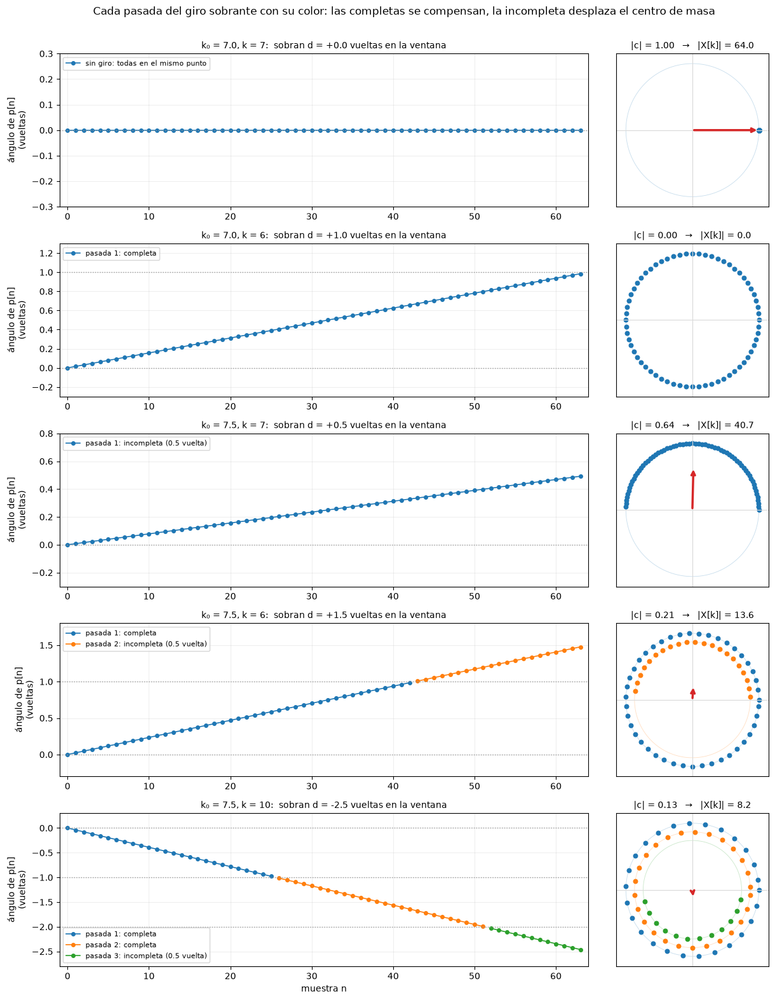

In [24]:
from matplotlib import colormaps
cmap_p = colormaps['tab10']
casos = [(7.0, 7), (7.0, 6), (7.5, 7), (7.5, 6), (7.5, 10)]    # (k0, k)

fig, axs = plt.subplots(len(casos), 2, figsize=(13, 3.2 * len(casos)), gridspec_kw={'width_ratios': [2.3, 1]})
for row, (k0, k) in enumerate(casos):
    x = np.exp(2j * np.pi * k0 * n / N)
    p = x * np.exp(-2j * np.pi * k * n / N)
    c = p.mean()
    dd = k0 - k                                   # giro sobrante (vueltas por ventana)
    vueltas = dd * n / N                          # ángulo acumulado del producto, en vueltas
    pasada = np.floor(np.abs(vueltas) + 1e-9).astype(int)
    ax_t, ax_z = axs[row]

    for m in range(pasada.max() + 1):
        sel = pasada == m
        completa = (m + 1) <= abs(dd) + 1e-9
        etiqueta = f'pasada {m + 1}: ' + ('completa' if completa else f'incompleta ({(abs(dd) - m):.1f} vuelta)')
        if dd == 0:
            etiqueta = 'sin giro: todas en el mismo punto'
        ax_t.plot(n[sel], vueltas[sel], 'o-', color=cmap_p(m), ms=4, lw=1.2, label=etiqueta)
        r_m = 1 - 0.13 * m                          # cada pasada en su anillo (solo para verlas por separado)
        ax_z.plot(r_m * np.cos(theta), r_m * np.sin(theta), color=cmap_p(m), lw=0.6, alpha=0.25)
        ax_z.scatter(r_m * p[sel].real, r_m * p[sel].imag, color=cmap_p(m), s=22, zorder=2 + m)

    for v in np.arange(-3, 4):
        ax_t.axhline(v, color='0.6', ls=':', lw=1)
    lo, hi = min(0, dd), max(0, dd)
    ax_t.set_ylim(lo - 0.3, hi + 0.3); ax_t.set_xlim(-1, N)
    ax_t.set_ylabel('ángulo de p[n]\n(vueltas)')
    ax_t.set_title(f'k₀ = {k0}, k = {k}:  sobran d = {dd:+.1f} vueltas en la ventana', fontsize=10)
    ax_t.legend(fontsize=8, loc='upper left' if dd >= 0 else 'lower left'); ax_t.grid(alpha=0.2)

    ax_z.annotate('', xy=(c.real, c.imag), xytext=(0, 0), arrowprops=dict(arrowstyle='->', color='tab:red', lw=2.5))
    ax_z.axhline(0, color='0.85', lw=0.8); ax_z.axvline(0, color='0.85', lw=0.8)
    ax_z.set_xlim(-1.15, 1.15); ax_z.set_ylim(-1.15, 1.15); ax_z.set_box_aspect(1)
    ax_z.set_xticks([]); ax_z.set_yticks([])
    ax_z.set_title(f'|c| = {abs(c):.2f}   →   |X[k]| = {N * abs(c):.1f}', fontsize=10)
axs[-1, 0].set_xlabel('muestra n')
fig.suptitle('Cada pasada del giro sobrante con su color: las completas se compensan, la incompleta desplaza el centro de masa')
plt.tight_layout(rect=(0, 0, 1, 0.975)); plt.show()

#### Los bins muestrean la curva del giro sobrante

El centro de masa depende **solo** del giro sobrante $d = k_0 - k$. Es la serie geométrica de la diapositiva 11, y su módulo es el **núcleo de Dirichlet**:

$$|c(d)| = \left|\frac{\sin(\pi d)}{N\,\sin(\pi d/N)}\right|$$

Es una sola curva, fija. La DFT solo la mira en los puntos $d = k_0 - k$ que tocan los bins:
- **en bin** ($k_0$ entero), los bins caen en $d$ enteros: **exactamente en los ceros** de la curva, salvo en $d=0$. Sale un único pico;
- **fuera de bin** ($k_0 = 7.5$), los bins caen en $d$ semienteros, **entre los ceros**: sobre los lóbulos. Por eso todos los bins tienen algo de energía.

Abajo se ve el espectro resultante $|X[k]| = N\,|c|$ en los dos casos, con la curva de Dirichlet superpuesta.

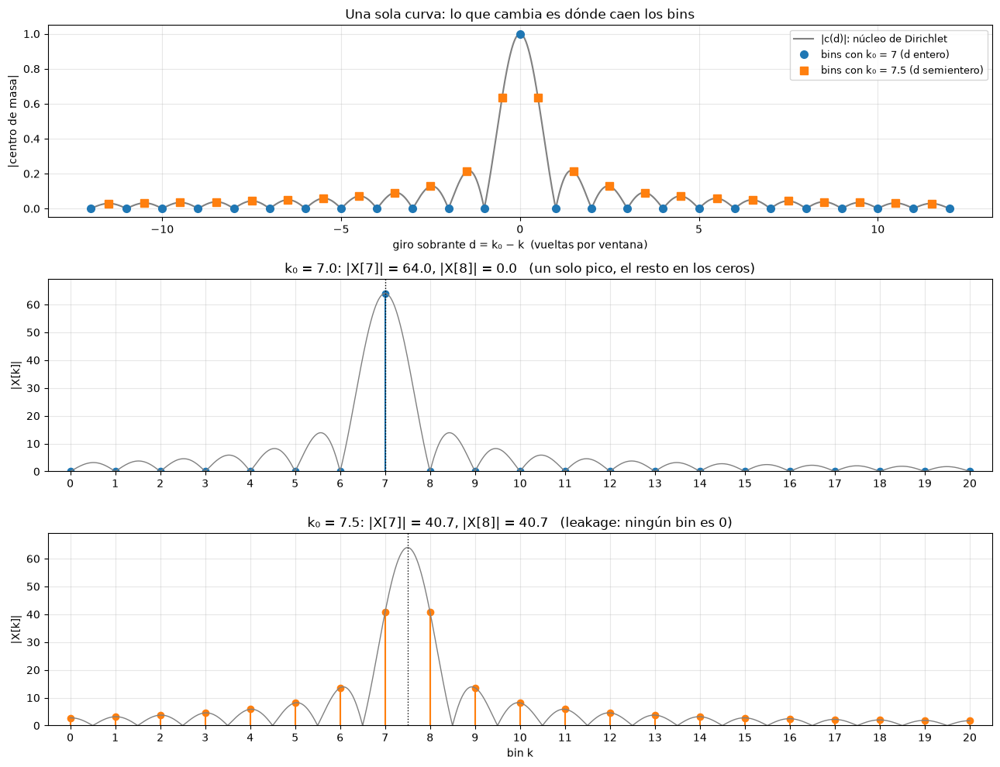

In [25]:
d = np.linspace(-12, 12, 4001)
with np.errstate(invalid='ignore', divide='ignore'):
    dir_curve = np.abs(np.sin(np.pi * d) / (N * np.sin(np.pi * d / N)))
dir_curve[np.isclose(d, 0)] = 1.0

fig, axs = plt.subplots(3, 1, figsize=(13, 10))
ax = axs[0]
ax.plot(d, dir_curve, color='0.5', lw=1.5, label='|c(d)|: núcleo de Dirichlet')
d_on = np.arange(-12, 13)
d_off = np.arange(-12, 12) + 0.5
ax.plot(d_on, np.abs(np.sinc(d_on)), 'o', color='tab:blue', ms=7, label='bins con k₀ = 7 (d entero)')
dir_off = np.abs(np.sin(np.pi * d_off) / (N * np.sin(np.pi * d_off / N)))
ax.plot(d_off, dir_off, 's', color='tab:orange', ms=7, label='bins con k₀ = 7.5 (d semientero)')
ax.set_xlabel('giro sobrante d = k₀ − k  (vueltas por ventana)'); ax.set_ylabel('|centro de masa|')
ax.set_title('Una sola curva: lo que cambia es dónde caen los bins')
ax.legend(fontsize=9); ax.grid(alpha=0.3)

kk = np.arange(N)
for ax, k0, col in [(axs[1], 7.0, 'tab:blue'), (axs[2], 7.5, 'tab:orange')]:
    X = np.fft.fft(np.exp(2j * np.pi * k0 * n / N))
    ax.stem(kk, np.abs(X), linefmt=col, markerfmt='o', basefmt=' ')
    kc = np.linspace(0, 20, 2001)
    dc = k0 - kc
    with np.errstate(invalid='ignore', divide='ignore'):
        curve = np.abs(np.sin(np.pi * dc) / np.sin(np.pi * dc / N))
    curve[np.isclose(dc, 0)] = N
    ax.plot(kc, curve, color='0.5', lw=1)
    ax.set_xlim(-0.5, 20.5); ax.set_ylim(0, N * 1.08)
    ax.set_xticks(range(0, 21))
    ax.set_ylabel('|X[k]|'); ax.grid(alpha=0.3)
    ax.axvline(k0, color='k', ls=':', lw=1)
    picos = ', '.join(f'|X[{k}]| = {abs(X[k]):.1f}' for k in [7, 8])
    ax.set_title(f'k₀ = {k0}: {picos}' + ('   (un solo pico, el resto en los ceros)' if k0 == int(k0) else '   (leakage: ningún bin es 0)'))
axs[2].set_xlabel('bin k')
plt.tight_layout(); plt.show()

## Resumen

| Imagen geométrica | Matemática |
|---|---|
| Distancia al origen en cada instante | $g(t)$ (o $x[n]$) |
| Girar alrededor del origen a $f$ vueltas/s | $e^{-2\pi i f t}$ (o $e^{-j2\pi kn/N}$) |
| Curva enrollada | $g(t)\,e^{-2\pi i f t}$ |
| Centro de masa | $c(f) = \frac1T\int g(t)e^{-2\pi i f t}dt$ |
| Transformada de Fourier | $G(f) = T\cdot c(f)$ ;  DFT: $X[k] = N\cdot c_k$ |
| Distancia del centro de masa al origen | magnitud del espectro |
| Ángulo del centro de masa | fase del espectro |

Si la velocidad de enrollamiento coincide con una frecuencia presente en la señal, la curva queda descompensada y el centro de masa se aleja del origen. **Eso es un pico en el espectro.**